# 干诺道西及西天桥 · 提前 30 分钟的检测点平均车速预测

**Connaught Road West and Flyover · 30-Minute-Ahead Detector Mean Speed Forecast**

在解压后的项目目录打开 Notebook，选择安装了项目依赖的内核，然后 Run All。运行单元直接调用本项目的 Python 模块。末尾源码附录逐文件保留完整实现，便于阅读、核对和交接。

预测目标为同一检测点在预测起点后第 30 分钟结束的 5 分钟加权平均车速。原始数据按车道存储，车道数用于覆盖率检查，速度差试验留作六周数据的候选敏感性分析。默认运行随包附带的三天原型。正式数据准备好后可设置 `CONNAUGHT_CONFIG=study`。

Open this notebook in the extracted project, select the Python environment with project dependencies, and choose Run All. The executable cells call the same modules as the CLI. The source appendix includes each complete package file for inspection and handover.

The target is the vehicle-weighted mean speed in the five-minute bin ending 30 minutes after the forecast origin at the same detector. Lane records support coverage checks and aggregation. The lane speed gap remains a candidate sensitivity analysis. The bundled three-day pilot runs by default. Set `CONNAUGHT_CONFIG=study` after preparing the study data.

- `CONNAUGHT_STAGE=eda` · 只运行开发期 EDA / Run development-only EDA.
- `CONNAUGHT_OUTPUT` · 指定独立输出目录 / Choose a separate output directory.
- `CONNAUGHT_PROJECT_ROOT` · 从项目外启动内核时指定目录 / Locate the project when the kernel starts elsewhere.


## 1. 加载配置 / Load configuration

In [1]:
import os
from pathlib import Path
import sys

base = Path(os.environ.get("CONNAUGHT_PROJECT_ROOT") or Path.cwd()).resolve()
root = next((path for path in (base, *base.parents)
             if (path / "src/connaught/pipeline.py").is_file()
             and (path / "configs/pilot.toml").is_file()), None)
if root is None:
    raise FileNotFoundError("Open the notebook in the project or set CONNAUGHT_PROJECT_ROOT.")
sys.path.insert(0, str(root / "src"))

from connaught.config import load_config
from connaught.eda import run_eda
from connaught.pipeline import run

config = load_config(root, os.environ.get("CONNAUGHT_CONFIG", "pilot"))
output_dir = os.environ.get("CONNAUGHT_OUTPUT")
stage = os.environ.get("CONNAUGHT_STAGE", "run")


## 2. 运行共用流程 / Run the shared pipeline

In [2]:
if stage == "eda":
    result = run_eda(root, config, output_dir)
elif stage == "run":
    result = run(root, config, output_dir)
else:
    raise ValueError("CONNAUGHT_STAGE must be run or eda.")
print(f"{stage} · {config['name']} · {result['output']}")


run · pilot · /Users/kevinkel/Documents/Codex/2026-10-28/en/work/connaught_modular/notebook_run


## 3. 查看覆盖率、结果和图表 / Review coverage, results and figures

Ablation: {'full_mae_improvement_kmh': 0.1146057780471474, 'test_days': 1, 'paired_daily_bootstrap_95pct': None}


,group,model,n,mae,rmse,bias,mae_gain_vs_persistence_pct
0,Overall,persistence,2454,3.8368,5.3523,0.0011,0.0000
1,Overall,historical,2454,3.6033,5.4009,-1.3040,6.0859
2,Overall,ridge_speed_only,2454,3.1788,4.4262,-0.2596,17.1490
3,Overall,ridge_full,2454,3.0642,4.2876,-0.0721,20.1360
4,Overall,random_forest,2454,3.0882,4.3233,-0.1473,19.5095


,detector_id,road_group,expected_bins,usable_bins,mean_lane_coverage,usable_share
0,AID03101,Flyover,864,823,0.7284,0.9525
1,AID03102,Surface,864,822,0.7284,0.9514
2,AID03103,Surface,864,822,0.7277,0.9514
3,AID03104,Surface,864,815,0.7253,0.9433
4,AID04102,Flyover,864,807,0.7216,0.9340
5,AID04103,Flyover,864,808,0.7213,0.9352
6,AID04104,Flyover,864,0,0.0000,0.0000
7,AID04105,Flyover,864,823,0.7284,0.9525
8,AID04218,Flyover,864,823,0.7284,0.9525
9,AID04219,Flyover,864,823,0.7281,0.9525


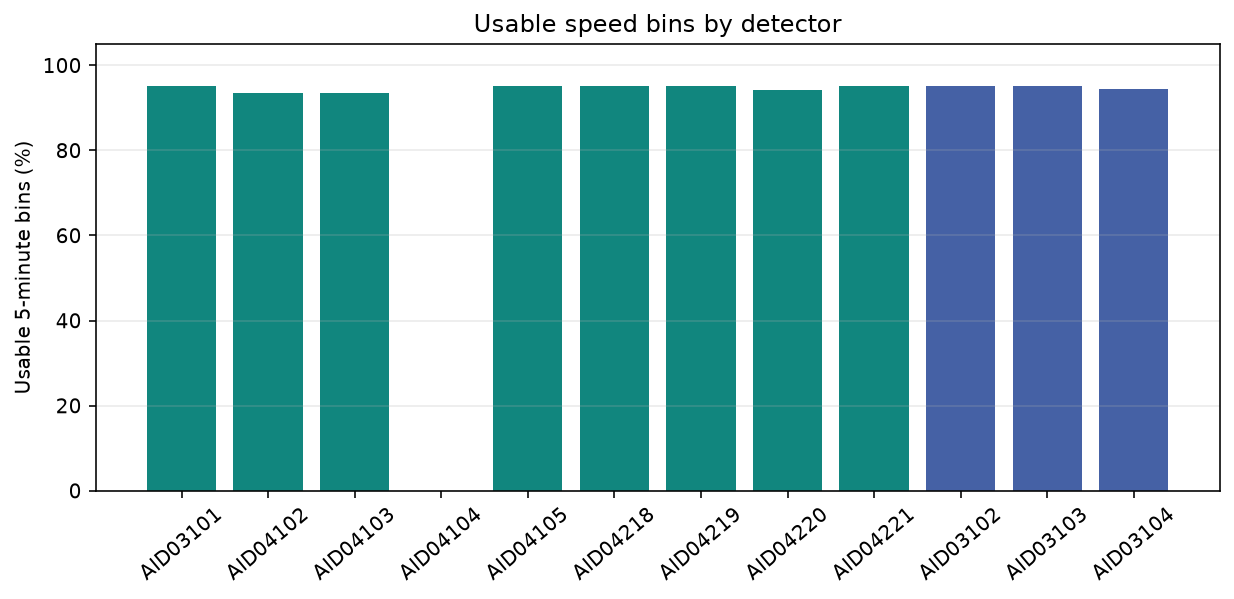

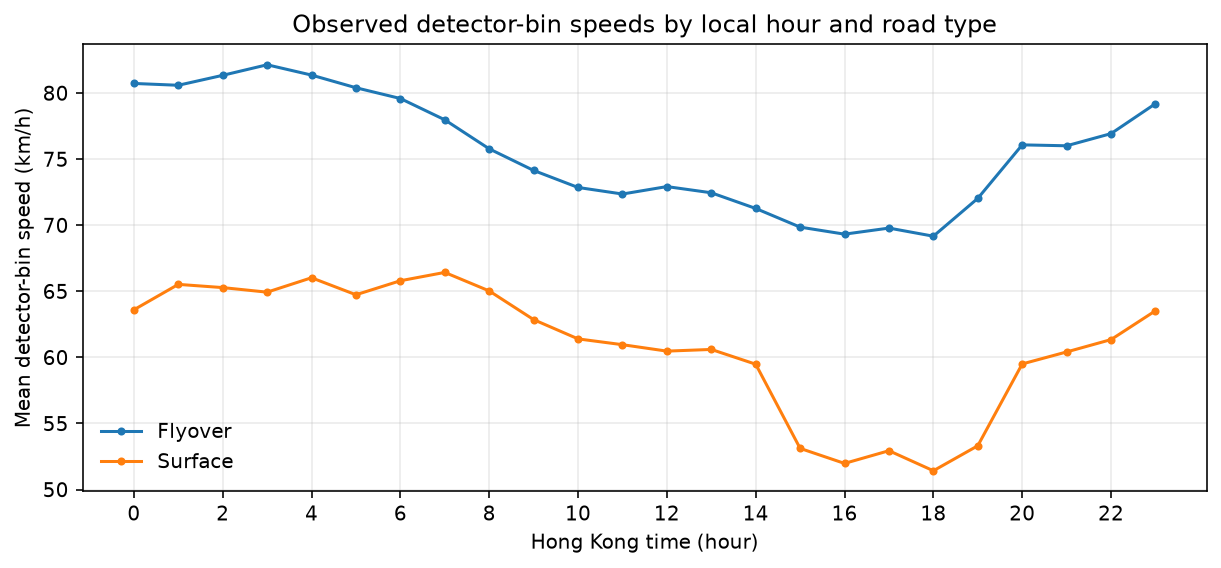

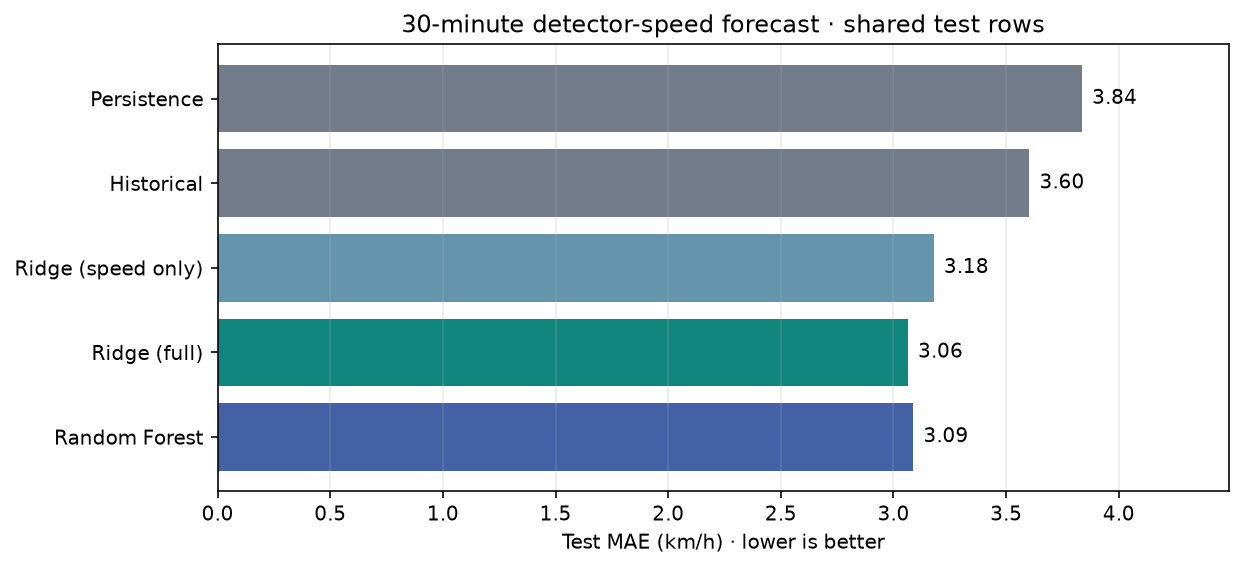

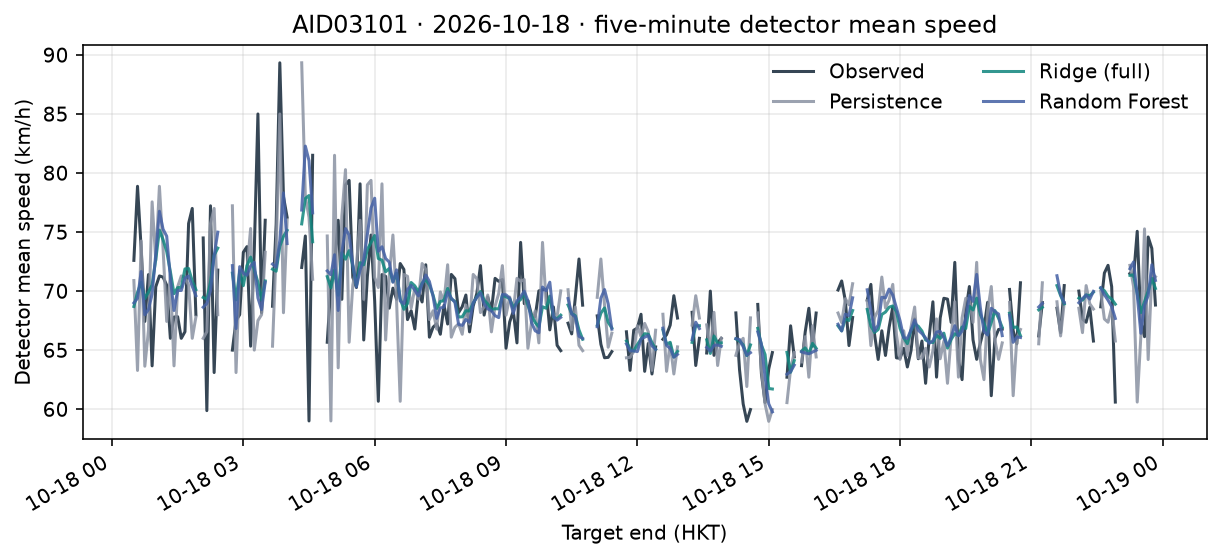

In [3]:
from IPython.display import Image, display

if "metrics" in result:
    display(result["metrics"].round(4))
    print("Ablation:", result["summary"]["ablation"])
display(result["coverage"].round(4))
for path in result["figures"].values():
    display(Image(filename=str(path)))


## 4. 源码附录 / Package source

这些是项目模块的逐字副本。修改源文件后，运行 `python tools/sync_notebook.py` 重新生成本文件。

These are verbatim module snapshots. Edit the package files and regenerate the notebook.

### `src/connaught/config.py`

````python
"""加载和验证实验配置。 / Load and validate experiment configuration."""

from pathlib import Path
import tomllib

import pandas as pd


def project_root(directory=None):
    """从项目根目录或任意子目录定位项目。 / Find the project from its root or any child directory."""
    base = Path(directory or Path.cwd()).resolve()
    for path in (base, *base.parents):
        if (path / "configs/pilot.toml").is_file():
            return path
    raise FileNotFoundError("Run from the extracted project directory or pass its path with --root.")


def load_config(root, name="pilot"):
    cfg_path = Path(name)
    if cfg_path.suffix != ".toml":
        cfg_path = Path("configs") / f"{name}.toml"
    path = root / cfg_path
    with path.open("rb") as stream:
        config = tomllib.load(stream)
    start, cut, end = (pd.Timestamp(config[key]) for key in ("start", "test_start", "end_exclusive"))
    if not start < cut < end:
        raise ValueError("Require start < test_start < end_exclusive.")
    if config["bin_minutes"] != 5 or config["horizon_minutes"] not in (15, 30, 60):
        raise ValueError("This workflow uses 5-minute bins and a 15/30/60-minute horizon.")
    if not 0 < config["min_coverage"] <= 1:
        raise ValueError("min_coverage must be in (0, 1].")
    if not config["ridge_alphas"] or not config["forest_leaf_sizes"]:
        raise ValueError("Model candidate lists cannot be empty.")
    for fold in config.get("validation", []):
        if not start < pd.Timestamp(fold["start"]) < pd.Timestamp(fold["end"]) <= cut:
            raise ValueError("Validation periods must lie inside the development period.")
    return config
````


### `src/connaught/artifacts.py`

````python
"""JSON 输出与来源校验。 / JSON output and provenance checks."""

import hashlib
import json


def write_json(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".part")
    temp.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    temp.replace(path)


def sha256_file(path):
    with path.open("rb") as file:
        return hashlib.file_digest(file, "sha256").hexdigest()
````


### `src/connaught/archives.py`

````python
"""官方归档查询、下载及车道 XML 提取。 / Discover, download and extract official lane archives."""

from concurrent.futures import ThreadPoolExecutor
import csv
import gzip
import json
from pathlib import Path
import shutil
import subprocess
from urllib.parse import urlencode
import xml.etree.ElementTree as ET
import zipfile

import pandas as pd

from .artifacts import sha256_file, write_json


SOURCE_XML = "https://resource.data.one.gov.hk/td/traffic-detectors/rawSpeedVol-all.xml"
ARCHIVE_API = "https://app.data.gov.hk/v1/historical-archive/"
DATA_COLUMNS = [
    "date", "period_from", "period_to", "detector_id", "direction", "lane_id",
    "speed", "volume", "occupancy", "speed_sd", "valid", "snapshot", "archive_day",
]


def archive_dates(config):
    return pd.date_range(config["start"], config["end_exclusive"], inclusive="left", freq="D").strftime("%Y%m%d").tolist()


def archive_url(endpoint, **params):
    return ARCHIVE_API + endpoint + "?" + urlencode({"url": SOURCE_XML, **params})


def fetch_archive_resource(url, destination=None):
    args = ["curl", "--fail", "--location", "--silent", "--show-error",
            "--connect-timeout", "20", "--max-time", "1800" if destination else "45",
            "--user-agent", "DSC5001-Connaught-Research/0.1"]
    if destination:
        args += ["--output", str(destination), "--write-out", "%{url_effective}"]
    if not shutil.which("curl"):
        raise RuntimeError("Online archive retrieval requires curl on PATH.")
    result = subprocess.run([*args, url], capture_output=True, check=False)
    if result.returncode:
        raise RuntimeError(result.stderr.decode("utf-8", errors="replace").strip())
    return result.stdout


def fetch_json(url):
    return json.loads(fetch_archive_resource(url))


def probe_archives(config):
    """核对逐日快照数量及官方 ZIP 归档方式。 / Check daily snapshot counts and the available official ZIP packaging."""
    def one_day(day):
        try:
            body = fetch_json(archive_url("list-file-versions", start=day, end=day))
            packages = body.get("data-files", [])
            bundle = next((f for f in packages if f.get("period") == "D" and f.get("timestamp") == day), None)
            if bundle is None:
                bundle = next((f for f in packages if f.get("period") == "M" and
                               str(f.get("timestamp", ""))[:6] == day[:6]), None)
            return {"day": day, "snapshot_versions": body.get("version-count"),
                    "official_package": bundle}
        except (OSError, ValueError, RuntimeError) as exc:
            return {"day": day, "error": str(exc)}

    with ThreadPoolExecutor(max_workers=4) as pool:
        return list(pool.map(one_day, archive_dates(config)))


def archive_members(archive, day_prefix=None):
    return sorted(name for name in archive.namelist() if name.lower().endswith(".xml")
                  and (not day_prefix or Path(name).name.startswith(day_prefix + "-")))


def download_archives(config, archive_dir, probe=None):
    """每个官方日档或月档只下载一次并复用。 / Download each advertised daily or monthly ZIP once and reuse it."""
    archive_dir.mkdir(parents=True, exist_ok=True)
    rows = probe if probe is not None else probe_archives(config)
    if [r["day"] for r in rows] != archive_dates(config):
        raise ValueError("Archive probe does not match configuration dates.")
    missing = [r["day"] for r in rows if not r.get("official_package") or not r.get("snapshot_versions")]
    if missing:
        raise ValueError(f"Missing advertised archives for {missing}. Review the probe before downloading.")
    verified = {}
    manifest = []
    for row in rows:
        day, bundle = row["day"], row["official_package"]
        key = bundle["timestamp"]
        month = bundle["period"] == "M"
        url = archive_url("get-file", time=key)
        path = archive_dir / (f"{key[:6]}-monthly.zip" if month else f"{day}.zip")
        if path not in verified:
            resolved = None
            advertised = int(bundle["size"])
            if not path.is_file():
                temp = path.with_suffix(".part")
                try:
                    resolved = fetch_archive_resource(url, temp).decode("utf-8")
                    if temp.stat().st_size != advertised or not zipfile.is_zipfile(temp):
                        raise ValueError(f"{path.name}: response does not match advertised ZIP.")
                    temp.replace(path)
                except RuntimeError as exc:
                    raise RuntimeError(f"{key}: {exc}. Retrieve the advertised ZIP "
                                       f"through DATA.GOV.HK and place it at {path}.") from exc
                finally:
                    temp.unlink(missing_ok=True)
            if path.stat().st_size != advertised:
                raise ValueError(f"{path.name}: cached size differs from official metadata.")
            with zipfile.ZipFile(path) as archive:
                members = archive_members(archive)
            verified[path] = (resolved, sha256_file(path), members)
        resolved, digest, members = verified[path]
        prefix = day if month else None
        count = sum(not prefix or Path(n).name.startswith(prefix + "-") for n in members)
        if count != row["snapshot_versions"]:
            raise ValueError(f"{day}: archive has {count} matching snapshots; API lists {row['snapshot_versions']}.")
        manifest.append({"day": day, "source_url": SOURCE_XML, "retrieval_url": url,
                         "resolved_url": resolved, "size_bytes": path.stat().st_size,
                         "sha256": digest, "version_count": count,
                         "archive_file": path.name, "member_day_prefix": prefix,
                         "origin": "official API" if resolved else "local archive cache"})
    return manifest


def prepare_lane_subset(root, config, archive_dir, manifest):
    """从每个归档流式读取目标检测器记录并保留快照来源。 / Stream selected detector rows from each archive and preserve snapshot lineage."""
    days = archive_dates(config)
    entries = {r["day"]: r for r in manifest}
    if set(days) != set(entries):
        raise ValueError("Manifest dates must match the configuration.")
    ids = set(pd.read_csv(root / config["detectors"], dtype=str)["detector_id"])
    hashes = {}
    for day in days:
        item = entries[day]
        path = archive_dir / item.get("archive_file", f"{day}.zip")
        if path not in hashes:
            hashes[path] = sha256_file(path)
        if path.stat().st_size != item["size_bytes"] or hashes[path] != item["sha256"]:
            raise ValueError(f"{path}: size or SHA-256 mismatch.")
    out = root / config["input"]
    out.parent.mkdir(parents=True, exist_ok=True)
    temp = out.with_suffix(".part")
    audit = []
    try:
        with gzip.open(temp, "wt", encoding="utf-8", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=DATA_COLUMNS)
            writer.writeheader()
            for day in days:
                totals = {"day": day, "snapshots": 0, "periods": 0, "selected_lane_rows": 0}
                item = entries[day]
                with zipfile.ZipFile(archive_dir / item.get("archive_file", f"{day}.zip")) as archive:
                    for member in archive_members(archive, item.get("member_day_prefix")):
                        try:
                            source = ET.fromstring(archive.read(member))
                            date = source.findtext("date")
                            periods = source.findall("./periods/period")
                            if not date or not periods:
                                raise ValueError("missing XML observation date or periods")
                            for period in periods:
                                start, end = (period.findtext(k) for k in ("period_from", "period_to"))
                                for detector in period.findall("./detectors/detector"):
                                    key = detector.findtext("detector_id")
                                    if key not in ids:
                                        continue
                                    for lane in detector.findall("./lanes/lane"):
                                        row = {k: lane.findtext(k) for k in ("lane_id", "speed", "volume", "occupancy", "valid")}
                                        row.update(date=date, period_from=start, period_to=end,
                                                   detector_id=key, direction=detector.findtext("direction"),
                                                   speed_sd=lane.findtext("s.d.") or lane.findtext("sd"),
                                                   snapshot=member, archive_day=day)
                                        writer.writerow(row)
                                        totals["selected_lane_rows"] += 1
                            totals["periods"] += len(periods)
                            totals["snapshots"] += 1
                        except (ET.ParseError, ValueError) as exc:
                            raise ValueError(f"{day}/{member}: {exc}") from exc
                if totals["snapshots"] != entries[day]["version_count"]:
                    raise ValueError(f"{day}: XML count differs from manifest.")
                audit.append(totals)
                print(f"{day}: {totals['snapshots']} XML, {totals['selected_lane_rows']:,} selected lane rows")
        temp.replace(out)
    finally:
        temp.unlink(missing_ok=True)
    write_json(root / config["manifest"], manifest)
    write_json(root / config["extraction_audit"], audit)
    return audit
````


### `src/connaught/preprocessing.py`

````python
"""清洗车道记录并生成五分钟检测点面板。 / Clean lane records and build five-minute detector panels."""

from pathlib import Path

import numpy as np
import pandas as pd

from .artifacts import sha256_file, write_json


def build_panel(root, config):
    """汇总同一检测点的合格车道记录。 / Aggregate valid lane observations within each detector."""
    input_path = root / config["input"]
    if not input_path.is_file():
        raise FileNotFoundError(f"Missing {input_path}. See README.md for preparation.")
    meta = pd.read_csv(root / config["detectors"], dtype={"detector_id": str})
    if meta["detector_id"].duplicated().any():
        raise ValueError("Detector IDs in the reference table must be unique.")
    raw = pd.read_csv(input_path, dtype={"detector_id": str, "archive_day": str})
    start, end = (pd.Timestamp(config[k]) for k in ("start", "end_exclusive"))
    raw["timestamp"] = pd.to_datetime(raw["date"] + " " + raw["period_from"], errors="coerce")
    raw["period_end"] = pd.to_datetime(raw["date"] + " " + raw["period_to"], errors="coerce")
    raw.loc[raw["period_end"] <= raw["timestamp"], "period_end"] += pd.Timedelta(days=1)
    in_window = raw["timestamp"].ge(start) & raw["timestamp"].lt(end)
    window = raw.loc[in_window].sort_values(["archive_day", "snapshot"], kind="stable")
    unknown = set(window["detector_id"]) - set(meta["detector_id"])
    if unknown:
        raise ValueError(f"Input has unmapped detectors: {sorted(unknown)}")
    dedup = window.drop_duplicates(["timestamp", "detector_id", "lane_id"], keep="last").copy()
    lane_counts = dedup.groupby("detector_id")["lane_id"].nunique().reindex(meta["detector_id"])
    for key in ("speed", "volume", "occupancy"):
        dedup[key] = pd.to_numeric(dedup[key], errors="coerce")
    eligible = (dedup["valid"].eq("Y") & dedup["speed"].between(0, 200) &
                dedup["volume"].ge(0) & dedup["occupancy"].between(0, 100) &
                dedup["lane_id"].notna() &
                dedup["period_end"].sub(dedup["timestamp"]).eq(pd.Timedelta(seconds=30)) &
                dedup["timestamp"].dt.second.isin([0, 30]))
    clean = dedup.loc[eligible].copy()
    clean["bin_end"] = clean["timestamp"].dt.floor("5min") + pd.Timedelta(minutes=5)
    # 以车辆数加权同一点位各车道的 30 秒车速。 / Weight each lane's 30-second speed by its vehicle count.
    clean["weighted_speed"] = clean["speed"] * clean["volume"]
    agg = clean.groupby(["detector_id", "bin_end"]).agg(
        valid_records=("speed", "size"), vehicles=("volume", "sum"),
        weighted_speed=("weighted_speed", "sum"), occupancy=("occupancy", "mean"),
    )
    time_grid = pd.date_range(start + pd.Timedelta(minutes=5), end, freq="5min")
    grid = pd.MultiIndex.from_product([meta["detector_id"], time_grid], names=["detector_id", "bin_end"])
    panel = agg.reindex(grid).reset_index()
    panel["expected_lanes"] = panel["detector_id"].map(lane_counts)
    panel["valid_records"] = panel["valid_records"].fillna(0).astype(int)
    panel["coverage"] = (panel["valid_records"] / (10 * panel["expected_lanes"])).fillna(0)
    if (panel["coverage"] > 1 + 1e-10).any():
        raise ValueError("Coverage > 1, check lane inventory and snapshot deduplication.")
    panel["speed"] = panel["weighted_speed"] / panel["vehicles"].where(panel["vehicles"].gt(0))
    panel["flow_per_lane_hour"] = panel["vehicles"] * 120 / panel["valid_records"].where(panel["valid_records"].gt(0))
    panel.loc[panel["coverage"].lt(config["min_coverage"]), ["speed", "flow_per_lane_hour", "occupancy"]] = np.nan
    panel = panel.drop(columns="weighted_speed").merge(meta, on="detector_id", validate="many_to_one")
    if not len(panel) or not panel["speed"].notna().any():
        raise ValueError("No usable speed bins. Check archive dates and coverage.")
    raw_summary = {
        "input_rows": len(raw), "missing_timestamps": int(raw["timestamp"].isna().sum()),
        "out_of_window_or_invalid_time": len(raw) - len(window), "duplicate_rows": len(window) - len(dedup),
        "invalid_or_offline_rows": len(dedup) - len(clean), "valid_lane_rows": len(clean),
        "registered_detectors": len(meta), "detectors_with_rows": len(lane_counts.dropna()),
        "usable_detectors": int(panel.loc[panel["speed"].notna(), "detector_id"].nunique()),
        "grid_rows": len(panel), "usable_bins": int(panel["speed"].notna().sum()),
        "sha256": sha256_file(input_path),
    }
    coverage = panel.groupby(["detector_id", "road_group"], as_index=False).agg(
        expected_bins=("bin_end", "size"), usable_bins=("speed", "count"), mean_lane_coverage=("coverage", "mean"))
    coverage["usable_share"] = coverage["usable_bins"] / coverage["expected_bins"]
    return panel, coverage, raw_summary


def daily_coverage(panel):
    day = (panel["bin_end"] - pd.Timedelta(seconds=1)).dt.strftime("%Y-%m-%d")
    table = panel.assign(date=day).groupby(["date", "detector_id", "road_group"], as_index=False).agg(
        expected_bins=("bin_end", "size"), usable_bins=("speed", "count"), mean_lane_coverage=("coverage", "mean"))
    table["usable_share"] = table["usable_bins"] / table["expected_bins"]
    return table

def write_coverage_outputs(panel, coverage, quality, output):
    """保存质量审计与覆盖率。 / Write data quality and coverage outputs."""
    coverage.to_csv(output / "detector_coverage.csv", index=False)
    daily_coverage(panel).to_csv(output / "daily_coverage.csv", index=False)
    write_json(output / "data_quality.json", quality)


def audit_coverage(root, config, output_dir=None):
    """清洗数据并输出覆盖率。 / Clean data and write coverage outputs."""
    output = Path(output_dir).resolve() if output_dir else root / config["output"]
    output.mkdir(parents=True, exist_ok=True)
    panel, coverage, quality = build_panel(root, config)
    write_coverage_outputs(panel, coverage, quality, output)
    return output
````


### `src/connaught/eda.py`

````python
"""独立运行开发期数据探索。 / Run development-period exploratory data analysis."""

from pathlib import Path

from .artifacts import write_json
from .plotting import save_eda_figures
from .preprocessing import build_panel, write_coverage_outputs


def write_eda_outputs(panel, coverage, quality, output):
    """保存覆盖率、质量统计和五分钟面板。 / Save coverage, quality and the five-minute panel."""
    write_coverage_outputs(panel, coverage, quality, output)
    panel.to_csv(output / "five_minute_panel.csv.gz", index=False,
                 compression={"method": "gzip", "mtime": 0})


def run_eda(root, config, output_dir=None, *, include_holdout=False):
    """默认只读取开发期观测。 / Restrict the EDA window to development by default."""
    scope = "all" if include_holdout else "development"
    eda_config = dict(config)
    if not include_holdout:
        eda_config["end_exclusive"] = config["test_start"]

    output = (Path(output_dir).resolve() if output_dir
              else root / config["output"] / "eda" / scope)
    output.mkdir(parents=True, exist_ok=True)
    panel, coverage, quality = build_panel(root, eda_config)
    write_eda_outputs(panel, coverage, quality, output)
    write_json(output / "eda_scope.json", {
        "scope": scope,
        "start": eda_config["start"],
        "end_exclusive": eda_config["end_exclusive"],
    })
    return {"output": output, "coverage": coverage, "figures": save_eda_figures(panel, output)}
````


### `src/connaught/features.py`

````python
"""特征、预测标签与时序切分。 / Features, forecast labels and chronological splits."""

import numpy as np
import pandas as pd


SPEED_FEATURES = ["speed", "speed_lag_5", "speed_lag_10", "target_sin", "target_cos", "target_weekend"]
# 车道数用于覆盖率，速度差试验收益不稳定。 / Lane count supports coverage. Speed-gap gains were inconsistent.
FULL_FEATURES = SPEED_FEATURES + ["flow_per_lane_hour", "occupancy"]


def make_examples(panel, config):
    """用同一检测点的未来 5 分钟均速作标签。 / Label each row with the future five-minute mean speed at the same detector."""
    frame = panel.sort_values(["detector_id", "bin_end"]).copy().rename(columns={"bin_end": "origin"})
    offsets = frame.groupby("detector_id")["origin"].diff().dropna()
    if not offsets.eq(pd.Timedelta(minutes=5)).all():
        raise ValueError("Expected complete five-minute grids for every detector.")
    speeds = frame.groupby("detector_id")["speed"]
    frame["speed_lag_5"] = speeds.shift(1)
    frame["speed_lag_10"] = speeds.shift(2)
    h = config["horizon_minutes"]
    frame["target_end"] = frame["origin"] + pd.Timedelta(minutes=h)
    frame["target_speed"] = speeds.shift(-(h // 5))
    minute = frame["target_end"].dt.hour * 60 + frame["target_end"].dt.minute
    frame["target_slot"] = minute // 5
    frame["target_hour"] = minute // 60
    frame["target_dow"] = frame["target_end"].dt.dayofweek
    frame["target_weekend"] = frame["target_dow"].ge(5).astype(int)
    frame["target_sin"] = np.sin(2 * np.pi * minute / 1440)
    frame["target_cos"] = np.cos(2 * np.pi * minute / 1440)
    frame["target_day"] = (frame["target_end"] - pd.Timedelta(seconds=1)).dt.strftime("%Y-%m-%d")
    frame["time_group"] = np.select(
        [frame["target_hour"].between(7, 9), frame["target_hour"].between(17, 19)],
        ["07:00–09:59", "17:00–19:59"], default="Other")
    return frame.dropna(subset=FULL_FEATURES + ["target_speed"]).reset_index(drop=True)


def split_at(examples, start, end):
    boundary, last = pd.Timestamp(start), pd.Timestamp(end)
    train = examples.loc[examples["target_end"].le(boundary)].copy()
    test = examples.loc[examples["origin"].ge(boundary) & examples["target_end"].le(last)].copy()
    if train.empty or test.empty:
        raise ValueError(f"Insufficient eligible rows for split at {boundary}.")
    if not train["target_end"].max() <= test["origin"].min():
        raise ValueError("Target leakage across split boundary.")
    return train, test
````


### `src/connaught/models.py`

````python
"""基线、Ridge、随机森林和时序选参。 / Benchmarks, Ridge, random forest and chronological tuning."""

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from .evaluation import evaluate
from .features import FULL_FEATURES, SPEED_FEATURES, split_at


def historical_baseline(train, test):
    """仅用训练数据计算典型车速，并记录分层回退规则。 / Training-only typical speed, with a documented backoff hierarchy."""
    prediction = np.full(len(test), np.nan)
    levels = np.full(len(test), "", dtype=object)
    hierarchy = [
        (["detector_id", "target_dow", "target_slot"], "point_weekday_slot"),
        (["detector_id", "target_weekend", "target_hour"], "point_daytype_hour"),
        (["detector_id", "target_hour"], "point_hour"),
        (["detector_id"], "point_median"),
    ]
    for keys, label in hierarchy:
        typical = train.groupby(keys, sort=False)["target_speed"].median().rename("typical")
        values = test[keys].join(typical, on=keys)["typical"].to_numpy()
        use = np.isnan(prediction) & np.isfinite(values)
        prediction[use], levels[use] = values[use], label
    missing = np.isnan(prediction)
    prediction[missing], levels[missing] = test["speed"].to_numpy()[missing], "persistence_fallback"
    return prediction, levels


def build_model(family, value, features, config):
    prep = ColumnTransformer([
        ("numeric", StandardScaler(), features),
        ("site", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["detector_id"]),
    ])
    if family == "ridge":
        estimator = Ridge(alpha=float(value))
    else:
        estimator = RandomForestRegressor(n_estimators=config["forest_trees"], min_samples_leaf=int(value),
                                          max_features=0.8, random_state=config["seed"], n_jobs=1)
    return make_pipeline(prep, estimator)


def choose_parameters(examples, config):
    families = [
        ("ridge_full", "ridge", config["ridge_alphas"], FULL_FEATURES),
        ("ridge_speed_only", "ridge", config["ridge_alphas"], SPEED_FEATURES),
        ("random_forest", "forest", config["forest_leaf_sizes"], FULL_FEATURES),
    ]
    folds = [split_at(examples, f["start"], f["end"]) for f in config.get("validation", [])]
    rows, selected = [], {}
    for label, family, candidates, features in families:
        if not folds and len(candidates) > 1:
            raise ValueError(f"{label}: multiple hyperparameters require validation folds.")
        means = []
        for value in candidates:
            fold_scores = []
            for i, (train, valid) in enumerate(folds, 1):
                model = build_model(family, value, features, config)
                cols = features + ["detector_id"]
                model.fit(train[cols], train["target_speed"])
                score = evaluate(valid["target_speed"], model.predict(valid[cols]))
                rows.append({"model": label, "parameter": value, "fold": i, **score})
                fold_scores.append(score["mae"])
            means.append(np.mean(fold_scores) if fold_scores else 0.0)
        selected[label] = (family, candidates[int(np.argmin(means))], features)
    return selected, pd.DataFrame(rows, columns=["model", "parameter", "fold", "n", "mae", "rmse", "bias"])


def predict_all(train, test, specs, config):
    pred = test[["detector_id", "road_group", "origin", "target_end", "target_day",
                 "target_weekend", "time_group", "speed", "target_speed"]].copy()
    pred["persistence"] = test["speed"]
    pred["historical"], pred["historical_level"] = historical_baseline(train, test)
    coefficients = pd.DataFrame()
    for label, (family, value, features) in specs.items():
        model = build_model(family, value, features, config)
        cols = features + ["detector_id"]
        model.fit(train[cols], train["target_speed"])
        pred[label] = model.predict(test[cols])
        if label == "ridge_full":
            names = model.named_steps["columntransformer"].get_feature_names_out()
            coefficients = pd.DataFrame({"feature": names, "coefficient": model.named_steps["ridge"].coef_})
    return pred.reset_index(drop=True), coefficients
````


### `src/connaught/evaluation.py`

````python
"""误差、分组、配对消融和按日重采样。 / Error metrics, subgroups, paired ablation and day resampling."""

import numpy as np
import pandas as pd


MODEL_NAMES = ["persistence", "historical", "ridge_speed_only", "ridge_full", "random_forest"]
MODEL_DISPLAY = {
    "persistence": "Persistence", "historical": "Historical", "ridge_speed_only": "Ridge (speed only)",
    "ridge_full": "Ridge (full)", "random_forest": "Random Forest",
}


def evaluate(true, prediction):
    delta = np.asarray(prediction) - np.asarray(true)
    return {"n": len(delta), "mae": float(np.mean(np.abs(delta))),
            "rmse": float(np.sqrt(np.mean(delta ** 2))), "bias": float(np.mean(delta))}


def score_table(pred, by=None):
    rows = []
    groups = pred.groupby(by, sort=True) if by else [("Overall", pred)]
    for key, part in groups:
        base = evaluate(part["target_speed"], part["persistence"])["mae"]
        for model in MODEL_NAMES:
            score = evaluate(part["target_speed"], part[model])
            rows.append({"group": str(key), "model": model, **score,
                         "mae_gain_vs_persistence_pct": 100 * (base - score["mae"]) / base if base else np.nan})
    return pd.DataFrame(rows)


def paired_ablation(pred, seed):
    difference = (pred["ridge_speed_only"] - pred["target_speed"]).abs() - (pred["ridge_full"] - pred["target_speed"]).abs()
    by_day = difference.groupby(pred["target_day"]).agg(["sum", "size"])
    interval = None
    if len(by_day) >= 7:
        rng = np.random.default_rng(seed)
        picks = rng.integers(0, len(by_day), size=(2000, len(by_day)))
        sims = by_day["sum"].to_numpy()[picks].sum(axis=1) / by_day["size"].to_numpy()[picks].sum(axis=1)
        interval = [float(v) for v in np.quantile(sims, [0.025, 0.975])]
    return {"full_mae_improvement_kmh": float(difference.mean()), "test_days": len(by_day),
            "paired_daily_bootstrap_95pct": interval}
````


### `src/connaught/plotting.py`

````python
"""原型 EDA 与预测诊断绘图。 / EDA and forecast diagnostics."""

import pandas as pd

from .evaluation import MODEL_DISPLAY



def _save_figure(plt, fig, folder, name):
    path = folder / f"{name}.png"
    fig.savefig(path, dpi=145, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return path


def save_eda_figures(panel, output):
    """生成覆盖率与小时车速图。 / Render coverage and hourly speed profiles."""
    from matplotlib import use
    use("Agg")
    from matplotlib import pyplot as plt

    folder = output / "figures"
    folder.mkdir(parents=True, exist_ok=True)
    figures = {}

    fig, ax = plt.subplots(figsize=(10, 4))
    sites = panel.groupby(["detector_id", "road_group"], as_index=False).agg(
        expected=("bin_end", "size"), usable=("speed", "count"))
    sites = sites.sort_values(["road_group", "detector_id"])
    ax.bar(sites["detector_id"], 100 * sites["usable"] / sites["expected"],
           color=["#11867e" if g == "Flyover" else "#4561a5" for g in sites["road_group"]])
    ax.set(title="Usable speed bins by detector", ylabel="Usable 5-minute bins (%)", ylim=(0, 105))
    ax.tick_params(axis="x", labelrotation=40)
    ax.grid(axis="y", alpha=.25)
    figures["01_detector_coverage"] = _save_figure(plt, fig, folder, "01_detector_coverage")

    fig, ax = plt.subplots(figsize=(10, 4))
    work = panel.assign(hour=(panel["bin_end"] - pd.Timedelta(seconds=1)).dt.hour)
    for group, part in work.groupby("road_group"):
        profile = part.groupby("hour")["speed"].mean().reindex(range(24))
        ax.plot(profile.index, profile.values, marker="o", markersize=3, label=group)
    ax.set(title="Observed detector-bin speeds by local hour and road type", ylabel="Mean detector-bin speed (km/h)",
           xlabel="Hong Kong time (hour)", xticks=range(0, 24, 2))
    ax.legend(frameon=False)
    ax.grid(alpha=.25)
    figures["02_hourly_profiles"] = _save_figure(plt, fig, folder, "02_hourly_profiles")

    return figures


def save_forecast_figures(pred, scores, output, config):
    """生成模型误差与预测示例图。 / Render model errors and an example forecast."""
    from matplotlib import use
    use("Agg")
    from matplotlib import pyplot as plt

    folder = output / "figures"
    folder.mkdir(parents=True, exist_ok=True)
    figures = {}

    fig, ax = plt.subplots(figsize=(9, 4))
    names = scores["model"].map(MODEL_DISPLAY)
    bars = ax.barh(names, scores["mae"], color=["#737c8b", "#737c8b", "#6495ad", "#11867e", "#4561a5"])
    ax.bar_label(bars, fmt="%.2f", padding=5)
    ax.set(xlabel="Test MAE (km/h) · lower is better", title=f'{config["horizon_minutes"]}-minute detector-speed forecast · shared test rows',
           xlim=(0, max(scores["mae"]) * 1.17))
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=.25)
    figures["03_model_comparison"] = _save_figure(plt, fig, folder, "03_model_comparison")

    site = pred["detector_id"].value_counts().index[0]
    day = sorted(pred.loc[pred["detector_id"].eq(site), "target_day"].unique())[0]
    sub = pred.loc[pred["detector_id"].eq(site) & pred["target_day"].eq(day)].set_index("target_end")
    times = pd.date_range(sub.index.min(), sub.index.max(), freq="5min")
    sub = sub.reindex(times)
    fig, ax = plt.subplots(figsize=(10, 4))
    for field, name, color in [("target_speed", "Observed", "#152839"), ("persistence", "Persistence", "#8b93a3"),
                               ("ridge_full", "Ridge (full)", "#11867e"), ("random_forest", "Random Forest", "#4561a5")]:
        ax.plot(sub.index, sub[field], label=name, color=color, alpha=.86)
    ax.set(title=f"{site} · {day} · five-minute detector mean speed", xlabel="Target end (HKT)", ylabel="Detector mean speed (km/h)")
    ax.legend(ncol=2, frameon=False)
    ax.grid(alpha=.25)
    fig.autofmt_xdate()
    figures["04_forecast_example"] = _save_figure(plt, fig, folder, "04_forecast_example")

    return figures


def save_figures(panel, pred, scores, output, config):
    return {**save_eda_figures(panel, output), **save_forecast_figures(pred, scores, output, config)}
````


### `src/connaught/reporting.py`

````python
"""生成可离线打开的中文团队报告。 / Generate the offline Chinese team report."""

from html import escape
import json

import pandas as pd

from .evaluation import MODEL_DISPLAY


def term(label):
    """以行内小字标注关键英文术语。 / Annotate key English terms inline."""
    return f'（<span class="term" lang="en">{escape(label)}</span>）'


def format_table(frame, columns):
    view = frame.rename(columns=columns)[list(columns.values())]
    return view.to_html(index=False, border=0, classes="data", escape=True, float_format=lambda v: f"{v:.3f}")


LANE_PILOT = [
    {"date": "2026-10-17", "comparison": "static_count", "n": 2543, "baseline_mae": 5.16383, "trial_mae": 5.15773},
    {"date": "2026-10-18", "comparison": "static_count", "n": 2454, "baseline_mae": 3.06419, "trial_mae": 3.06286},
    {"date": "2026-10-17", "comparison": "gap_matched", "n": 2225, "baseline_mae": 5.95768, "trial_mae": 5.94204},
    {"date": "2026-10-18", "comparison": "gap_matched", "n": 2136, "baseline_mae": 2.92387, "trial_mae": 2.92283},
    {"date": "2026-10-17", "comparison": "gap_all_rows", "n": 2543, "baseline_mae": 5.16383, "trial_mae": 5.22271},
    {"date": "2026-10-18", "comparison": "gap_all_rows", "n": 2454, "baseline_mae": 3.06419, "trial_mae": 3.06707},
]


def build_lane_decision():
    """展示试验依据和车道口径。 / Present the lane trial and the resulting design decision."""
    labels = {
        "static_count": "加入车道数",
        "gap_matched": "加入速度差（共同可用样本）",
        "gap_all_rows": "加入速度差及可用标记（全样本）",
    }
    rows = []
    for row in LANE_PILOT:
        label = labels[row["comparison"]]
        rows.append(
            f'<tr><td>{label}</td><td>{row["date"]}</td><td>{row["n"]:,}</td>'
            f'<td>{row["baseline_mae"]:.3f}</td><td>{row["trial_mae"]:.3f}</td></tr>'
        )
    return f"""
<section id="lane-decision">
<h2>车道方案与取舍</h2>
<article class="explainer" id="guide-lanes">
<h3>怎么读车道速度差{term('lane speed gap')}的两种比较？</h3>
<p>「共同可用样本」先挑出至少两条车道可以计算均速的预测行，再让两版 Ridge 在相同训练和测试子集上比较。它回答的是「速度差能算出来时，加入它有没有帮助」。10 月 18 日只有 2,136 条符合条件，其中地面点的覆盖率低于天桥点。</p>
<p>「全样本」让新增特征的模型也处理速度差缺失的预测行，回答的是「把这套做法用于所有现有预测，整体会不会更准」。表中两种比较的基准 MAE 对应不同样本，应在同一行读试验前后的变化。逐车道预测还需要为每条车道单独定义未来标签并核查可用性，目前的主问题聚焦在同一检测点的整体均速。</p>
</article>
<p>原始 XML 按检测点、车道和 30 秒记录。三天原型的 12 个点中，1／2／3／4 条车道标签分别对应 1／6／4／1 个点。四车道点 AID04104 没有可用车速箱。现有方案用各点的车道数计算数据覆盖率，再按车辆数加权合并有效记录，生成点位级 5 分钟均速。</p>
<p>额外试验以预测起点最近一个完整 5 分钟窗为输入。每条车道至少有 6 条有效记录、且至少记录到 1 辆车。至少两条车道满足条件时，用最高与最低车道均速之差作为特征。10 月 18 日 2,454 条测试行中，2,136 条（87.0%）可计算速度差。下表按日期留出，用相同 Ridge 参数比较。全样本版本加入可用标记，并用各折训练期的平均速度差填充缺失。</p>
<div class="scroll"><table class="data"><thead><tr>
<th>试验</th><th>留出日</th><th>样本数</th>
<th>对照 MAE（km/h）</th><th>试验 MAE（km/h）</th>
</tr></thead><tbody>{"".join(rows)}</tbody></table></div>
<p class="note"><strong>主分析保留检测点级预测。</strong> 车道数加入模型后，两天 MAE 的降幅都小于 0.01 km/h。速度差在共同样本上的收益很小，10 月 18 日地面点误差略升，全样本版本两天均变差。因此，车道用于质量检查、聚合和候选敏感性分析，逐车道预测或以车道为独立单位的分析暂不纳入主方案。六周数据可用后，再检验速度差能否在多个日期和点位带来稳定增益。</p>
</section>"""


def build_team_guide(study):
    """生成小组导读与提案工作台。 / Build the team guide and proposal workspace."""
    start, end = (pd.Timestamp(study[k]) for k in ("start", "end_exclusive"))
    expected = 12 * (end - start).days * (24 * 60 // study["bin_minutes"])
    return f"""
<section id="team-start">
<div class="chapter-label">01 · 项目导读</div>
<h2>先统一我们要回答的问题</h2>
<article class="explainer" id="guide-why">
<h3>为什么已经知道当前车速，还要看流量和占用率？</h3>
<p>想象两个检测点现在都显示 50 km/h。一个点车辆较少，另一个点在同一时段通过了更多车辆，而且检测区域在更长的时间里被车辆占据。它们的当前均速相同，接下来半小时的变化却可能不同。我们比较加入这两项信号前后的预测，看看模型能否更好地分辨这两种情况。</p>
<p>预测单位是有明确位置和方向的检测点。这样，预测和实测能在同一个点直接对上，也能分开检查地面与天桥的表现。三天原型用来确认这套流程能从原始档案跑到结果表。六周实验才用来检验改善能否跨周、跨点位重复。</p>
</article>
<p>我们想知道，给定一个干诺道西或西天桥检测点的近期车速，加入同一时点可用的流量和道路占用率{term('traffic flow and occupancy')}后，能否更准确地预测半小时后的车速。潜在使用场景是出发前比较不同出发时段。项目逐点预测<strong>检测点平均车速</strong>，供分析该走廊的交通状况。</p>
<p class="note"><strong>预测指标口径</strong>　预测目标是每个检测点在目标 5 分钟内的车辆数加权平均车速（km/h）。汇总该点覆盖车道的有效 30 秒观测，每条观测以其车辆数加权。每个点独立输出，汇总范围止于单个检测点。流量（辆/车道/小时）和占用率（%）是输入特征。</p>
<div class="guide-grid">
<div><h3>范围</h3><p>干诺道西地面及西天桥的运输署检测点。干诺道中另行核验，提案按目前可核验的范围拟稿。</p></div>
<div><h3>目标</h3><p>每隔 5 分钟预测一次。例如 08:00 发出的预测对应 同一检测点 08:25–08:30 的车辆数加权平均车速，单位为 km/h。</p></div>
<div><h3>进度</h3><p>三天原型已用官方实测档案跑通。六周归档索引已预检，仍需核对点位逐日有效覆盖并完成正式实验。</p></div>
</div>
<p class="note"><strong>组员阅读顺序</strong>　先看下方<a href="#project-flow">项目流程</a>，再到<a href="#proposal-workbench">Proposal 工作台</a>认领写作与复核。需要核对说法时，从目录直达原型的数据、方法或结果。</p>

</section>
<section id="project-flow">
<div class="chapter-label">02 · 项目流程</div>
<h2>从官方观测到可复核的结论</h2>
<article class="explainer" id="guide-rows">
<h3>从原始记录到结果表，每一行是什么意思？</h3>
<div class="scroll"><table class="data"><thead><tr><th>阶段</th><th>一行的含义</th><th>用它回答什么</th></tr></thead><tbody>
<tr><td>车道原始记录</td><td>一个检测点的一条车道，在一个 30 秒时段内的车速、车辆数和占用率。</td><td>这一小段观测是否有效，应该以多少辆车参与加权。</td></tr>
<tr><td>5 分钟面板</td><td>一个检测点在一个 5 分钟时段的聚合结果。即使没拿到有效观测，也保留相应的时间位置。</td><td>当前车速及历史车速应该在什么时间取值。</td></tr>
<tr><td>预测结果</td><td>一个检测点的一次预测。记录预测起点、目标窗口结束时间、实际均速及各模型的预测值。</td><td>同一次预测，各模型分别差了多少。</td></tr>
</tbody></table></div>
<p>保留缺失的时间位置有实际作用。比如 07:55 缺了，08:00 的「5 分钟前车速」就应缺失。如果删掉空行再取上一行，就可能误用 07:50 的车速。</p>
</article>
<ol class="flow">
<li><strong>提取原始观测</strong>　官方归档 ZIP → 30 秒车道 XML → 目标检测点记录。核对源文件哈希、点位 ID、车道 ID 和香港时间。<a href="#sources">来源与档案清单</a></li>
<li><strong>生成检测点面板</strong>　筛除无效观测、去重、按检测点与 5 分钟聚合。检查有效车道覆盖率，保留缺测时段与异常点记录。<a href="#data">清洗与覆盖率</a></li>
<li><strong>对齐输入与目标</strong>　以检测点和预测起点为键，用当期和历史输入预测同点位的未来车速。日历特征可提前取得。<a href="#scope">预测例子</a></li>
<li><strong>按时间训练与比较</strong>　先用 Persistence 和历史中位数定参照，再比较 Ridge 与随机森林。开发期滚动选参，冻结后用同一批留出行评分。<a href="#method">模型与时间切分</a></li>
<li><strong>把每个问题对应到一项证据</strong>　RQ1 看共同样本模型误差，RQ2 看两版 Ridge 的配对 MAE 差值，RQ3 看点位、时段等分组的 MAE 和样本数。<a href="#result">原型证据示例</a></li>
</ol>
<div class="scroll"><table class="data"><thead><tr><th>想核对什么</th><th>打开哪个文件</th><th>先检查什么</th></tr></thead><tbody>
<tr><td>研究范围和数据能否支撑问题</td><td><code>data/reference/detectors.csv</code><br><code>daily_coverage.csv</code></td><td>点位、日期和有效覆盖。正式分析前先审计，再锁定样本范围。</td></tr>
<tr><td>时间切分及模型能否公平比较</td><td><code>summary.json</code><br><code>cv_scores.csv</code><br><code>predictions.csv</code></td><td>开发和测试边界，及各模型是否使用同一组预测行。原型使用固定参数。</td></tr>
<tr><td>怎样回答 RQ1–RQ3</td><td><code>model_metrics.csv</code><br><code>summary.json</code><br><code>errors_by_group.csv</code></td><td>整体 MAE、消融差值的正负、分组样本数和误差。</td></tr>
</tbody></table></div>
<p class="subtle">原型结果文件位于 <code>results/pilot/</code>。六周实验的结果将单独写入 <code>results/study/</code>。<a href="#reproduce">复现命令与交接检查</a></p>

</section>
<section id="proposal-workbench">
<div class="chapter-label">03 · 提案工作台</div>
<h2>按模板分工，合并成一份 Proposal</h2>
<article class="explainer" id="guide-writing">
<h3>合稿时，把每个问题接到一项可以交付的证据</h3>
<ul>
<li><strong>RQ1　模型有没有比简单方法更准？</strong> 方法段写清两个基线如何产生预测。结果计划里承诺同一张表、同一批测试样本、同一种 MAE 计算口径。</li>
<li><strong>RQ2　流量和占用率有没有额外价值？</strong> 用同一种 Ridge 比较两套输入。把两项变量作为一组加入，再按预测行比较误差。这个实验回答的是它们的联合增益。</li>
<li><strong>RQ3　改善出现在什么地方、什么时间？</strong> 约定按地面、天桥、点位和目标时段拆表，同时交出样本数。读者才能判断结论来自许多观测，还是来自少数样本。</li>
</ul>
<p>合稿时把已经完成的原型写成实测证据，把六周窗口写成待执行的方案。例如可以写「三天原型表明流程可以运行。我们将在六周实验的后两周评估误差是否稳定下降。」</p>
</article>
<p>用下方<a href="#proposal">中文讨论稿</a>统一口径，再按课程模板整理提交稿。Proposal 阶段先交代科学问题、数据可行性和验证计划。引用原型时注明三天数据、一天留出测试，六周结果留待正式实验。</p>
<h3>组会先确认四项</h3>
<ol>
<li><strong>提交信息</strong>　确认组名、组号、提交日期、五人姓名与 UID，并指定一位合稿人。</li>
<li><strong>范围和主问题</strong>　确认干诺道西及西天桥、检测点级、30 分钟预测时距和 5 分钟目标箱。优先定稿 RQ1 与 RQ2，组员也可保留 RQ3 作为分组分析。</li>
<li><strong>数据准入和评估</strong>　确认候选六周日期、逐日覆盖审核责任、共同测试样本、MAE 主指标。组内商定若某点或日期覆盖不足，如何在正式测试前记录调整。</li>
<li><strong>写作节奏</strong>　建议认领后 24 小时交初稿，再安排一轮交叉核对。项目最终提交日期与 Proposal 自身的交稿安排分开记，后者请在课程平台确认。</li>
</ol>
<h3>五人交付与互审</h3>
<div class="scroll"><table class="data"><thead><tr><th>建议主笔</th><th>负责模板</th><th>交给合稿人的材料</th><th>交叉核对</th></tr></thead><tbody>
<tr><td>A · 数据与溯源</td><td>§3 Data、数据引用</td><td>来源链接与查询日期、观察单位、理论网格和有效样本区别、覆盖风险</td><td>B 核对点位及方向描述</td></tr>
<tr><td>B · 范围、EDA、基线</td><td>§1 背景、§2 研究问题、§4 基线</td><td>2–4 句动机、2–3 个可检验问题、两种基线各一句</td><td>A 核对数据能否支持问题</td></tr>
<tr><td>C · Ridge 与消融</td><td>§4 Ridge、§5 解释性</td><td>两版输入、共同样本的配对 MAE、标准化系数的解释边界</td><td>D 核对输入口径与调参条件</td></tr>
<tr><td>D · 随机森林与验证</td><td>§4 随机森林、§5 验证与稳健性</td><td>开发与测试时间边界、扩展窗口、指标、覆盖率敏感性计划</td><td>C 核对泄漏风险和比较公平性</td></tr>
<tr><td>E · 评估、合稿与提交</td><td>封面、§6 贡献、§7 时间表、References</td><td>合并提交稿、核对原型与正式计划措辞、整理成员资料及最终 PDF</td><td>A–D 各核对自己的数据或方法描述</td></tr>
</tbody></table></div>
<h3>按 Proposal 模板逐项落稿</h3>
<ol>
<li>封面用问题式标题，填组名、提交日、五人的姓名、UID 和职责。背景用 2–4 句回答「谁会用、用来做什么、现在缺什么」，然后列 2–3 个可检验问题。</li>
<li>数据段写清运输署来源、链接、访问日期、六周候选窗口和观察单位。注明连续响应单位 km/h、主要特征、缺测与时间泄漏风险。把 {expected:,} 行写成理论网格大小，正式有效样本数留待数据审计。</li>
<li>方法与验证段按「简单基线 → 可解释 Ridge → 灵活随机森林」写，并把共同样本、两折时序验证、MAE 和稳健性检查与 RQ 对应。解释部分可规划标准化系数和正式报告中的变量解释图。</li>
<li>贡献、限制、四周时间表和参考资料各自交代。将原型证据与六周计划分别标明。Proposal 交稿时间在课程平台核对。</li>
</ol>
<h3>交稿前逐项核对</h3>
<ul>
<li>封面信息和成员表已填齐。背景 2–4 句，研究问题 2–3 个，各自对应具体比较。</li>
<li>数据段列出来源、查询日期、观察单位、近似规模、响应变量、主要输入与已知问题。理论行数与实际有效行数分别注明。</li>
<li>验证段说明开发期选参、最终时间留出、共同测试行、主指标、解释与稳健性。原型数字若引用，注明仅对应原型测试日。</li>
<li>课程模板要求替换蓝色占位符、删除灰色指导文字，Proposal 至少半页，保存为 <code>Team-XX-Proposal.pdf</code>，其中 <code>XX</code> 替换为实际组号。</li>
<li>课程模板所列项目最终截止为 2026 年 11 月 29 日 23:59。将最多 10 页的展示、约 8 分钟录屏和代码附录纳入第 4 周，至少预留一天。</li>
</ul>

</section>"""


def build_proposal(study):
    start, end = (pd.Timestamp(study[k]) for k in ("start", "end_exclusive"))
    last = end - pd.Timedelta(days=1)
    test = pd.Timestamp(study["test_start"])
    days = (end - start).days
    return f"""
<section id="proposal"><h2>项目提案 · Proposal 讨论稿</h2>
<p class="note">供组员确认选题与实验计划。下方原型报告保留已完成的数据处理、模型与实测结果。六周方案用于后续正式实证。</p>
<p><b>拟定题目</b>　流量与道路占用率能否改善干诺道西及西天桥各检测点提前 30 分钟的平均车速预测？</p>
<details><summary>提案英文标题备选</summary><p lang="en">Do Traffic Flow and Road Occupancy Improve 30-Minute-Ahead Detector-Level Mean Speed Forecasts on Connaught Road West and Its Flyover?</p></details>
<p><b>小组名、提交日期</b>　由组员确认后填写。</p>
<div class="scroll"><table class="data"><thead><tr><th>成员</th><th>UID</th><th>拟负责内容</th></tr></thead><tbody>
<tr><td>成员 A（待填姓名）</td><td>待填</td><td>官方归档、数据清洗和覆盖率</td></tr>
<tr><td>成员 B（待填姓名）</td><td>待填</td><td>点位范围、EDA 和历史基线</td></tr>
<tr><td>成员 C（待填姓名）</td><td>待填</td><td>Ridge、特征消融和解释</td></tr>
<tr><td>成员 D（待填姓名）</td><td>待填</td><td>随机森林、滚动验证和稳健性</td></tr>
<tr><td>成员 E（待填姓名）</td><td>待填</td><td>评估、Notebook 复现、报告与展示协调</td></tr>
</tbody></table></div>
<h3>1. 背景与动机</h3>
<p>半小时后的交通状态可能与当前车速不同，尤其在常态时段过渡到高峰时。对在出发前比较路线或出发时刻的人，提前 30 分钟的预测能提供更早的信息。项目检验近期车速是否已经足以预测这一时距，以及当期流量、道路占用率能否带来稳定的额外改善。</p>
<h3>2. 研究问题</h3>
<ol><li><b>RQ1</b>　在未见日期，Ridge 或随机森林能否降低相对 Persistence 和历史时段中位数基线的 MAE？</li>
<li><b>RQ2</b>　相对于只用近期车速、日历和点位的 Ridge，加入当期流量和占用率后，配对 MAE 是否下降？</li>
<li><b>RQ3</b>　上述改善在地面／天桥、目标时段和不同日期之间是否一致？</li></ol>
<h3>3. 数据</h3>
<p>来源为香港运输署主要道路原始交通数据和检测器位置表，2026 年 11 月 6 日查询候选归档索引。候选窗口为 {start.date()} 至 {last.date()}，共 {days} 天。按已确认的 12 个登记点、每天 288 个 5 分钟箱计算，理论网格约 {12*288*days:,} 行。模型行数还取决于检测器实际在线、覆盖率、非零车辆数、滞后特征与未来标签的完整性。 <a href="https://data.gov.hk/en-data/dataset/hk-td-sm_4-traffic-data-strategic-major-roads">运输署数据目录</a></p>
<p>每个样本对应一个检测点与预测起点。连续响应为同一检测点在起点后第 30 分钟结束的 5 分钟内，按车辆数加权的跨车道平均车速（km/h）。流量与占用率是输入特征。完整模型有 8 项数值或二元输入，包括当期及 5／10 分钟前的车速、两个时段周期特征、周末标记、当期流量和占用率。另加点位 ID 作为类别特征。重点核对缺测、时间对齐、有效车道数变化和干诺道中覆盖。</p>
<p>车道数用于覆盖率，各车道车速按车辆数合并。两天原型的车道速度差试验收益小且不稳定，因此主方案保持检测点级预测。详见<a href="#lane-decision">车道试验</a>。</p>
<h3>4. 拟采用方法</h3>
<p><b>RQ1</b> 用当前车速和训练期历史中位数建立两个基线，再比较 Ridge 与随机森林。Ridge 提供线性正则化比较，随机森林允许非线性和交互。<b>RQ2</b> 在共同样本和同一 Ridge 参数网格下比较两组输入。<b>RQ3</b> 从同一组预测明细计算点位、道路类别、日期及目标时段误差。</p>
<h3>5. 验证与评价</h3>
<p>{start.date()} 至 {(test-pd.Timedelta(days=1)).date()} 用于开发和扩展窗口验证，从 {test.date()} 至 {last.date()} 留作最终测试。每折的训练目标时间不超过下一评估区间的起点，所有模型统一使用完整测试行，验证以平均 MAE 选参。最终同时报告 MAE、RMSE 和平均偏差。用标准化 Ridge 系数及配对消融解释结果。按日期的配对重采样区间在测试天数足够时计算。</p>
<p>拟检查 60% 主覆盖率门槛和替代门槛下的留存率、点位构成与误差。先在开发阶段确定备选口径，正式测试分组统一汇报样本数，避免把样本选择差异误读为模型改善。</p>
<h3>6. 预期贡献与限制</h3>
<p>量化增加流量及占用率后，半小时预测在哪些场景更有帮助，以及简单模型在这个走廊能达到什么表现。结论限于可观测点位与所选日期。数据来自观测档案，特征增益不能解释为交通政策的因果效应。实时应用需另行量化观测发布延迟。</p>
<h3>7. 时间表</h3>
<div class="scroll"><table class="data"><thead><tr><th>建议阶段（2026）</th><th>组内里程碑</th></tr></thead><tbody>
<tr><td>11 月 6–9 日</td><td>锁定点位范围，查档、清洗、输出逐日覆盖率和 EDA。</td></tr>
<tr><td>11 月 10–16 日</td><td>对齐基线、Ridge 和随机森林，完成开发期滚动验证。</td></tr>
<tr><td>11 月 17–22 日</td><td>冻结配置，运行最终测试、消融和分组误差检查，整理结论。</td></tr>
<tr><td>11 月 23–28 日</td><td>整理不超过 10 页的展示、约 8 分钟录屏和代码附录，复现后尽量在 28 日提交。</td></tr>
</tbody></table></div>
<p>课程模板列出的最终提交时间为 2026 年 11 月 29 日 23:59。小组可按实际分工调整中间日期。</p>
<p><b>参考资料</b>　<a href="https://data.gov.hk/en-data/dataset/hk-td-sm_4-traffic-data-strategic-major-roads">香港运输署数据（查询日期 2026-11-06）</a> · <a href="https://otexts.com/fpp3/toolbox.html#time-series-cross-validation">Forecasting: Principles and Practice</a> · <a href="https://arxiv.org/pdf/1707.01926#page=5">DCRNN 多时距车速基准</a>。完整来源见下方<a href="#sources">资料来源</a>。</p>

</section>"""


def build_main_report_guide():
    """映射课程最终报告的十页结构。 / Map the ten-page final-report template to project evidence."""
    return f"""
<section id="main-report">
<div class="chapter-label">04 · 最终报告</div>
<h2>按课程模板组织最终报告和录屏</h2>
<p class="subtle">课程材料为 <code>Team-XX-Proposal-Template.pdf</code> 与 <code>Team-XX-Main-Report-Template.pdf</code>。</p>
<p>Proposal 用来确认选题、数据可行性和实验设计。Main Report 则用正式留出集的证据回答研究问题。下表是本项目的逐页写作底稿。「已有」指原型或现有流程可以提供的材料。「待补」指正式交稿前要生成或填写的内容。</p>
<p class="note">模板上限为 <strong>10 页，含封面</strong>。第 2–10 页标注讲者与参考时长。Proposal 模板列出的最终项目截止为 <strong>2026 年 11 月 29 日 23:59</strong>，要求至少预留一天。展示录屏约 <strong>8 分钟</strong>。</p>
<div class="scroll"><table class="data"><thead><tr>
<th>页码与参考时长</th><th>建议页面内容</th><th>已有材料与待补工作</th>
</tr></thead><tbody>
<tr><td>1 · 封面</td><td>课程全名、问题式项目标题、姓名与 UID、组名和日期。可加一行副标题，交代运输署数据和 30 分钟预测。</td><td>已有<a href="#proposal">项目标题</a>。组员确认课程全名和封面信息，导出前清理占位符和指导文字。</td></tr>
<tr><td>2 · 动机与研究问题 · 0:45</td><td>从出发时间选择切入，说明只看当前车速可能遗漏即将发生的变化。列出 RQ1 模型对照、RQ2 流量与占用率的联合增益、RQ3 分点位与时段的表现。</td><td>可用<a href="#team-start">项目导读</a>及<a href="#scope">研究范围</a>。正式版用一句标题概括为什么值得研究。</td></tr>
<tr><td>3 · 数据与清洗 · 0:45</td><td>列来源、链接、查询日期、时间范围、观察单位、连续响应、主要特征和已知风险。用两张小表区分车道原始行的逐步筛除，以及 5 分钟时间窗到建模行的变化。</td><td>已有<a href="#data">原型清洗台账</a>及 <code>data_quality.json</code>、<code>daily_coverage.csv</code>、<code>summary.json</code>。正式版换成六周计数，并补记每条正式过滤规则删除了多少行。</td></tr>
<tr><td>4 · EDA 与模型决策 · 0:45</td><td>放 2–3 张图，每张配一句「看见了什么、因此怎么建模」。覆盖率图对应点位纳入规则，分道路类型的小时图对应时间特征和分组评估。</td><td>已有 <code>01_detector_coverage.png</code> 和 <code>02_hourly_profiles.png</code>。正式版用开发期数据重画，避免看完测试集再决定特征。</td></tr>
<tr><td>5 · 模型阶梯与验证 · 0:50</td><td>从 Persistence 与历史中位数，过渡到普通线性回归 OLS、Ridge 和随机森林。用日期轴画出两折扩展窗口、最终留出期、MAE 选参及随机种子。</td><td>已有<a href="#method">两个基线、Ridge、随机森林与时序切分</a>。OLS 是第 6 页所需的无正则线性对照，目前待实现。模板里的 GAM 等属于可选示例。</td></tr>
<tr><td>6 · 可解释模型 · 0:40</td><td>展示基线、OLS 和 Ridge 的误差与一张带正负号的系数图。用一句话解释数值变量系数对应的单位及方向。</td><td><code>ridge_coefficients.csv</code> 已有。正式版补 OLS 对照和标准化 Ridge 系数图。当前标准化数值系数表示其他输入固定时，变量增加一个训练期标准差对应的预测变化，单位为 km/h。</td></tr>
<tr><td>7 · 完整模型比较 · 0:55</td><td>一行一个模型。列关键超参数、共同开发折的 CV 指标均值 ± 标准差、测试指标与 95% 自助法区间{term("bootstrap interval")}、拟合耗时。若区间明显重叠，谨慎表述差别。</td><td><code>cv_scores.csv</code> 支持学习模型的逐折汇总，<code>predictions.csv</code> 支持按目标日期做成组重采样。待补基线的共同折评分、逐模型区间和拟合耗时。现有 Ridge 消融区间针对两版的差值。</td></tr>
<tr><td>8 · 变量解释 · 0:55</td><td>用置换重要性{term('permutation importance')}回答「哪些变量对预测有用」，用部分依赖图{term('partial dependence plot')}解释「模型预测怎样随某个变量变化」。结合交通场景说明方向，使用关联措辞。</td><td>已有标准化 Ridge 系数。置换重要性与部分依赖图待补。可先考虑把相关的近期车速特征作为一组，并在有观测支持的范围内解释占用率。</td></tr>
<tr><td>9 · 稳健性 · 0:40</td><td>至少放一项子群比较和一项替代清洗规则。建议用地面与天桥分组，并把 60% 覆盖率与开发期预先锁定的备选门槛对照，例如 70%，分别汇报留存、MAE 和结论是否变化。</td><td><code>errors_by_group.csv</code> 与<a href="#lane-decision">车道试验</a>已有原型证据。正式替代门槛待跑。比较时同时报告各口径原样本及两者共有样本，便于分辨清洗与样本构成的影响。</td></tr>
<tr><td>10 · 结论、建议与限制 · 0:50</td><td>按 RQ1–RQ3 各给一句直接回答和正式数字。给目标使用者 2–3 条由结果支持的建议，列限制和一项可做的后续工作。注明 <code>Team-[XX]-Appendix.pdf</code>。</td><td>待六周评分后定稿。可为出发时段比较者讨论在何种时段采用预测、何时同时看当前车速、以及对覆盖稀疏点位如何注明证据范围。限制包括点位覆盖、观测关联和实时发布延迟。</td></tr>
</tbody></table></div>
<h3>第 10 页怎么写成有数字的回答</h3>
<p>下面是写法示例，数字取自 10 月 18 日的一天原型测试。正式报告用六周实验最后两周的结果替换。</p>
<ul>
<li><strong>RQ1。</strong> 完整 Ridge 的 MAE 为 3.064 km/h，Persistence 为 3.837 km/h，原型误差降低约 20.1%。正式报告还需结合模型区间判断差别是否稳定。</li>
<li><strong>RQ2。</strong> 同一批样本加入流量与占用率后，Ridge 的 MAE 从 3.179 降到 3.064 km/h，配对差约 0.115 km/h。</li>
<li><strong>RQ3。</strong> 原型地面点和天桥点的配对改善分别约 0.026 和 0.149 km/h，对应 684 和 1,770 条预测。正式版应连同分时段结果和样本数呈现。</li>
</ul>
<h3>附录如何做到逐项复现</h3>
<p>为每张最终图表或结果写下一条对应关系，包含页码、图表名称、配置、运行命令、输出文件和代码位置。预测误差可追到 <code>predictions.csv</code>，清洗行数可追到质量统计与面板。项目组确认组号后，将可复现代码汇入附录 PDF，并在第 10 页标出。</p>
</section>"""


def build_report(config, summary, coverage, scores, grouped, cv, coefficients, figures, manifest, study, archive_probe=None):
    import base64

    raw = summary["data"]
    split = summary["split"]
    ablation = summary["ablation"]
    after_time = raw["input_rows"] - raw["out_of_window_or_invalid_time"]
    after_dedup = after_time - raw["duplicate_rows"]
    grid_unusable = raw["grid_rows"] - raw["usable_bins"]
    metrics = scores.copy()
    metrics["model"] = metrics["model"].map(MODEL_DISPLAY)
    compare = format_table(metrics, {
        "model": "方法", "n": "共同测试行", "mae": "MAE（km/h）", "rmse": "RMSE（km/h）",
        "bias": "平均偏差（预测−实测）", "mae_gain_vs_persistence_pct": "相对 Persistence 的 MAE 改善（%）",
    })
    by_group = grouped.copy()
    by_group["model"] = by_group["model"].map(MODEL_DISPLAY)
    group_table = format_table(by_group, {
        "dimension": "维度", "group": "子组", "model": "方法", "n": "样本", "mae": "MAE", "rmse": "RMSE",
    })
    site_table = format_table(coverage, {
        "detector_id": "检测器", "road_group": "道路类型", "expected_bins": "应有时间箱",
        "usable_bins": "可用车速箱", "mean_lane_coverage": "平均车道记录覆盖", "usable_share": "可用车速比例",
    })
    c = ablation["paired_daily_bootstrap_95pct"]
    uncertainty = (f"按完整测试日期做 2,000 次配对区块重采样，95% 区间为 [{c[0]:.3f}, {c[1]:.3f}] km/h。"
                   if c else "当前测试日期数不足 7 天，未计算区间。相邻 5 分钟样本以及同一日期的多点记录存在相关性。")
    param_text = escape(json.dumps(summary["selected_parameters"], ensure_ascii=False))
    history_levels = escape(json.dumps(summary["historical_levels"], ensure_ascii=False))
    cv_html = (format_table(cv, {"model": "方法", "parameter": "参数", "fold": "时序折", "n": "验证行",
                                 "mae": "MAE", "rmse": "RMSE"})
               if len(cv) else "<p>三天原型使用预先固定的参数。未运行滚动调参。</p>")
    prov_html = format_table(pd.DataFrame(manifest), {
        "day": "档案日期", "size_bytes": "档案字节", "version_count": "XML 数", "sha256": "SHA-256",
    })
    best = scores.sort_values("mae").iloc[0]
    ridge = scores.set_index("model").loc["ridge_full"]
    base = scores.set_index("model").loc["persistence"]
    if archive_probe is None:
        probe_html = "<p>六周档案的逐日元数据与实际数据覆盖应分别检查。</p>"
    else:
        days_available = sum(bool(row.get("snapshot_versions") and row.get("official_package")) for row in archive_probe)
        packages = {row["official_package"]["filename"]: row["official_package"]
                    for row in archive_probe if row.get("official_package")}
        package_gb = sum(int(p["size"]) for p in packages.values()) / 10**9
        probe_html = (f"<p>官方元数据预检返回 {days_available} / {len(archive_probe)} 天的归档与版本信息。"
                      f"涉及 {len(packages)} 个去重归档包，官方公布压缩大小约 {package_gb:.2f} GB。"
                      "预检只核对归档索引，干诺道有效覆盖仍需解包后逐日统计。</p>")

    def figure(key, caption):
        data = base64.b64encode(figures[key].read_bytes()).decode("ascii")
        return f'<figure><img alt="{escape(caption)}" src="data:image/png;base64,{data}"><figcaption>{escape(caption)}</figcaption></figure>'

    return f'''<!doctype html>
<html lang="zh-CN"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>{escape(config["title"])} · DSC5001</title>
<style>
:root{{color-scheme:light;--ink:#142738;--muted:#496374;--line:#d5e0e6;--teal:#086e65;--paper:#f2f6f7}}
*{{box-sizing:border-box}}body{{margin:0;color:var(--ink);background:var(--paper);font:16px/1.72 system-ui,"PingFang SC","Microsoft YaHei",sans-serif}}main{{max-width:1080px;margin:auto;padding:40px 22px 58px}}h1,h2,h3{{line-height:1.25}}h1{{font-size:clamp(28px,5vw,52px);margin:10px 0}}h2{{font-size:25px;margin-top:0}}h3{{margin:20px 0 8px}}.hero{{padding:30px;background:#112c3b;color:#fff;border-radius:16px}}.hero p{{color:#e1eef4}}.tag{{font-size:13px;letter-spacing:.08em;font-weight:700;color:#8ce2d3}}.stats{{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:10px;margin-top:20px}}.stats div{{padding:14px;background:#234354;border-radius:9px}}.stats strong{{display:block;font-size:24px}}nav{{display:flex;flex-wrap:wrap;gap:10px 20px;padding:18px 0}}a{{color:var(--teal);text-underline-offset:3px}}section{{background:white;border:1px solid var(--line);border-radius:12px;padding:22px 25px;margin:0 0 16px;scroll-margin-top:15px}}.note{{padding:10px 14px;background:#e8f5f3;border-left:4px solid #0c8176}}.scroll{{overflow-x:auto}}.scroll table{{min-width:650px}}table{{border-collapse:collapse;width:100%;font-size:14px}}th,td{{text-align:left;vertical-align:top;padding:8px;border-bottom:1px solid var(--line);overflow-wrap:anywhere}}th{{background:#eaf0f4}}pre{{white-space:pre-wrap;background:#edf3f6;padding:13px;border-radius:6px;overflow-wrap:anywhere}}code{{overflow-wrap:anywhere}}figure{{margin:18px 0}}img{{display:block;max-width:100%;height:auto}}figcaption,footer{{color:var(--muted);font-size:14px}}details{{margin:12px 0}}summary{{cursor:pointer;font-weight:650}}@media(max-width:570px){{main{{padding:16px 11px}}section,.hero{{padding:17px}}.stats{{grid-template-columns:1fr}}}}

.chapter-label{{font-size:12px;font-weight:750;letter-spacing:.07em;color:var(--teal);margin-bottom:8px}}
.guide-grid{{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:12px;margin:16px 0}}
.guide-grid>div{{padding:13px 16px;background:#f3f7f8;border:1px solid var(--line);border-radius:8px}}
.guide-grid h3{{font-size:16px;margin:0 0 6px}}.guide-grid p{{margin:0}}
.flow li{{padding:4px 0 8px}}.subtle{{color:var(--muted);font-size:14px}}
.section-nav{{font-weight:650}}.nav-divider{{color:var(--muted);font-weight:600}}
@media(max-width:680px){{.guide-grid{{grid-template-columns:1fr}}.nav-divider{{flex-basis:100%}}}}

.term{{font-size:.9em;color:var(--muted)}}

.explainer{{margin:18px 0;padding:16px 18px;background:#f4f8f9;border:1px solid var(--line);border-radius:9px}}
.explainer h3:first-child{{margin-top:0}}.explainer > :last-child{{margin-bottom:0}}
.explainer li{{margin-bottom:.7em}}.explainer li:last-child{{margin-bottom:0}}
@media(max-width:570px){{.explainer{{padding:13px}}}}
</style></head>
<body><main>
<header class="hero"><div class="tag">DSC5001 · 项目工作报告 · {escape(config["name"].upper())}</div>
<h1>{escape(config["title"])}</h1><p>{escape(config["status"])}。研究目标是比较不同方法在未见日期的车速误差，并量化流量和占用率在近期车速之外的增量价值。</p>
<div class="stats"><div><strong>{raw["usable_bins"]:,}</strong>可用 5 分钟车速箱</div><div><strong>{split["test_n"]:,}</strong>共同测试样本</div><div><strong>{ridge["mae"]:.3f}</strong>完整 Ridge MAE · km/h</div></div></header>
<nav aria-label="报告目录"><a class="section-nav" href="#team-start">项目导读</a><a class="section-nav" href="#project-flow">项目流程</a><a class="section-nav" href="#proposal-workbench">Proposal 工作台</a><a href="#proposal">Proposal 讨论稿</a><a class="section-nav" href="#main-report">Main Report 逐页计划</a><span class="nav-divider">原型详报</span><a href="#scope">研究范围</a><a href="#data">数据与清洗</a><a href="#lane-decision">车道方案</a><a href="#method">模型与验证</a><a href="#result">实测结果</a><a href="#reproduce">复现与分工</a><a href="#sources">资料来源</a></nav>
{build_team_guide(study)}
{build_proposal(study)}
{build_main_report_guide()}
<section id="scope"><h2>研究范围与问题</h2>
<article class="explainer" id="guide-clock">
<h3>读懂预测起点、预测提前量和目标窗口{term('forecast origin, horizon, target window')}</h3>
<p>以 08:00 发出的一次预测为例，08:00 是预测起点。当前车速对应 07:55–08:00，两个历史输入对应 07:50–07:55 和 07:45–07:50。往后推 30 分钟得到目标结束时间 08:30，因此用于评分的真实车速取自 08:25–08:30。</p>
<p>08:30 属于哪个时段、当天是否周末，在 08:00 就可以从日历得知。08:25–08:30 的实测车速、流量和占用率则来自未来。代码用未来均速作为训练标签，用可在预测时点取得的观测作为输入。</p>
</article>
<p>目前研究范围为干诺道西地面及西天桥的运输署检测点。干诺道中需要另外核实路段编号、方向与同期历史车速，尚未纳入主样本。路段车速与车道级原始数据的变量口径不同，后续若纳入应另建可比的车速实验。</p>
<ol><li>提前 {config["horizon_minutes"]} 分钟预测时，Ridge 或随机森林能否在未见日期稳定超过 Persistence 与历史时段基线？</li>
<li>在相同预测起点和目标上，加入当期流量及道路占用率，能否降低 Ridge 的绝对误差？</li>
<li>效果是否随检测点、地面／天桥或目标时段变化？分组结果反映现有点位与样本分布。</li></ol>
<p class="note">以 30 分钟设置为例，08:00 使用截至该时刻的观测，预测同一检测点 08:25–08:30 的平均车速。每 5 分钟可以重新生成一次预测。这里采用归档观测时间，实时部署还要核查发布延迟。</p>
</section>
<section id="data"><h2>来源、清洗与覆盖率</h2>
<article class="explainer" id="guide-aggregation">
<h3>用真实窗口复算一次车辆数加权平均车速{term('vehicle-count-weighted mean speed')}</h3>
<p>在 2026 年 10 月 18 日 00:00–00:05，天桥检测点 <code>AID03101</code> 有 3 条车道，每条车道每 30 秒预期 1 条记录，因此一共应有 30 条。该窗口有 24 条有效记录，覆盖率为 80%。有效记录合计 18 辆车。把每条记录的车速乘以车辆数后相加，得到 1,139，再除以 18，得到 <strong>63.28 km/h</strong>。这是原型面板中该窗口的车速。</p>
<p>覆盖率衡量的是传感器记录的完整程度。零车但有效的记录会计入覆盖率，在车速平均里的权重是零。整个窗口总车数为零，或覆盖率低于设定门槛，均速都记为缺失。流量则将车数按有效观测时长折算成每车道每小时的速率。占用率衡量检测区域被车辆占用的时间比例。</p>
<p>读下面两张图时，先看哪些点位经常能得到可用的 5 分钟均速，再看这些可用时段里车速怎样随小时变化。小时图对合格的检测点时间窗等权平均，因此记录更多的点可能对曲线贡献更多。</p>
</article>
<p>数据区间为 <b>{escape(config["start"])}</b> 至 <b>{escape(config["end_exclusive"])}</b>（后者为排除边界，香港时间）。运输署原始 XML 按检测器和车道记录 30 秒观测。随包输入是从档案中提取的指定点位车道记录，包含源快照名称和档案日期。</p>
<ol><li>以 XML 观测时间为准筛选研究窗口。按开始时间、检测器、车道去重，快照重复时保留排序后最后一条。</li>
<li>仅用 <code>valid=Y</code> 且满足数值范围、30 秒时长和时间栅格要求的记录。注册 {raw["registered_detectors"]} 个点，{raw["usable_detectors"]} 个有可用车速箱。</li>
<li>每点 5 分钟覆盖率＝有效车道记录数 ÷（期间观测到的车道数 × 10）。阈值为 {config["min_coverage"]:.0%}。如果正式档案内车道布局变化，须审核分母是否需要按日期更新。</li>
<li>每个检测点在每个 5 分钟箱内，将各覆盖车道有效 30 秒观测的「车速 × 车辆数」求和，再除以这些观测的总车辆数。总车数为零时车速缺失。流量是车辆数除以有效车道观测时长后折算的每车道小时率；占用率为合格车道记录的均值。缺失不插值。</li></ol>
<p>原始子集 {raw["input_rows"]:,} 行。窗口外或时间无效 {raw["out_of_window_or_invalid_time"]:,} 行，重复 {raw["duplicate_rows"]:,} 行，无效或离线 {raw["invalid_or_offline_rows"]:,} 行，最后保留 {raw["valid_lane_rows"]:,} 条有效车道记录。完整网格 {raw["grid_rows"]:,} 行。</p>
<h3>第 3 页清洗台账</h3>
<div class="scroll"><table class="data"><thead><tr><th>筛选步骤</th><th>去除车道行</th><th>保留车道行</th></tr></thead><tbody>
<tr><td>读入档案子集</td><td>—</td><td>{raw["input_rows"]:,}</td></tr>
<tr><td>限定窗口及可解析起始时间</td><td>{raw["out_of_window_or_invalid_time"]:,}</td><td>{after_time:,}</td></tr>
<tr><td>同时间、点位和车道去重</td><td>{raw["duplicate_rows"]:,}</td><td>{after_dedup:,}</td></tr>
<tr><td>检查有效标记、数值范围、车道和 30 秒时间规则</td><td>{raw["invalid_or_offline_rows"]:,}</td><td>{raw["valid_lane_rows"]:,}</td></tr>
</tbody></table></div>
<p>聚合后计量单位改成「检测点 × 5 分钟」。完整网格 {raw["grid_rows"]:,} 个窗口，其中 {grid_unusable:,} 个没有可用车速，留下 {raw["usable_bins"]:,} 个可用车速窗口。随后还要满足滞后输入、未来标签和时间边界。最终进入本次训练与测试的分别是 {split["train_n"]:,} 行和 {split["test_n"]:,} 行。车道行、检测点窗口、模型样本分开计数。当前质量输出合并记录最后一组检查的总移除数，正式报告若需逐规则展开，应先定义审计顺序，记录每步新增删除的行数。</p>
{probe_html}
{figure("01_detector_coverage","点位覆盖率。青色为天桥，蓝色为地面。图中比例指可用车速箱占理论网格的比例。")}
<details><summary>展开检测器覆盖率与缺失情况</summary><div class="scroll">{site_table}</div></details>
{figure("02_hourly_profiles","按道路类别及观测小时描述样本车速，每条合格的检测器时间箱等权。原型仅三天，曲线用于描述。")}

</section>
{build_lane_decision()}
<section id="method"><h2>模型、特征与时间切分</h2>
<article class="explainer" id="guide-methods">
<h3>为什么先做基线，再做 Ridge 和随机森林？</h3>
<p><strong>Persistence</strong> 把当前均速直接当成预测。路况变化不大时，这个简单方法往往有竞争力。<strong>历史中位数</strong>则用训练期相似时段的典型车速。它检验每天重复出现的时段规律是否已经足够。</p>
<p><strong>Ridge</strong> 把近期车速、时间、点位等信息组合成一个预测。相邻的车速输入通常相近，Ridge 对过大的系数加惩罚，有助于让估计更稳定。<strong>随机森林</strong>{term("random forest")}通过多棵决策树平均预测，可以表达「低速时占用率上升」等条件组合。两者使用相同的完整输入时，结果差异主要反映模型形式在这些样本上的表现。</p>
<h3>为什么按日期往后验证{term('time-series validation')}？</h3>
<p>实际使用时，模型只能用过去预测未来，所以开发和测试都按时间顺序。以午夜作为分界时，一条 23:45 发出的预测，其目标窗口结束于 00:15。虽然起点在分界前，它的标签来自分界后，因此不会进入这个切分的训练集。正式实验在前四周内做两次向后滚动的验证，再固定参数，用后两周评分。</p>
</article>
<ul><li><b>Persistence</b> 使用当前 5 分钟车速。</li>
<li><b>Historical</b> 使用训练期同点位、同星期与目标时段的中位数。按点位＋日类＋小时、点位＋小时、点位中位数逐级回退，最终可用 Persistence。测试回退计数为 <code>{history_levels}</code>。</li>
<li><b>Ridge</b> 输入当前及 5／10 分钟前车速、目标时刻的周期编码、目标日是否周末与点位编码。完整版本额外加入当期流量和占用率。标准化和编码均在各自训练部分拟合。</li>
<li><b>Random Forest</b> 使用与完整 Ridge 一致的输入。在相同测试起点比较非线性模型能否降低误差。</li></ul>
<p>以 <b>{escape(config["test_start"])} 00:00</b> 为边界。训练样本的目标箱结束时间不晚于边界，测试起点不早于边界。目标来自同一检测器在精确时距后的网格。所有模型使用共同的完整行，避免把缺失数据差异当作模型差异。训练 {split["train_n"]:,} 行，测试 {split["test_n"]:,} 行，测试涉及 {split["test_detectors"]} 个点、{split["test_days"]} 个目标日期。</p>
<p>参数 <code>{param_text}</code>。六周配置只在开发期两次扩展窗口中按平均 MAE 选参，冻结后在后两周评分。</p>
<details><summary>查看验证折结果或原型参数说明</summary><div class="scroll">{cv_html}</div></details>

</section>
<section id="result"><h2>实测结果与证据边界</h2>
<article class="explainer" id="guide-results">
<h3>怎么从单次误差读到整体结果？</h3>
<p>假设某点实测为 50 km/h，一个模型报 54，另一个报 46。两次的绝对误差都是 4 km/h，但前者高估、后者低估。把每行绝对误差平均就是 <strong>平均绝对误差（MAE）</strong>，它描述平均偏离多少。<strong>均方根误差（RMSE）</strong> 对较大的误差更敏感。<strong>平均偏差</strong>{term("mean signed error")}则保留正负号，帮助判断是否经常偏高或偏低。</p>
<p>原型中还可以找到一个具体的反例。10 月 18 日 00:00，<code>AID03101</code> 的目标实测为 72.60 km/h。Persistence 预测 70.89，完整 Ridge 预测 68.70，绝对误差分别约为 1.71 和 3.90 km/h。单次预测由 Persistence 胜出，即使完整 Ridge 在整批测试样本上的平均误差更小。</p>
<p>看结果表时，可先比较两种基线和学习模型，再看加入流量与占用率后同一批样本的误差差值。最后看改善是否集中在少数点或时段。相邻时段和同一天的点位可能一起受交通变化影响，因此原型的一天测试应当作为初步证据。正式结果需要结合多天的表现与按日重采样区间阅读。</p>
</article>
<p>表中的整体 MAE 汇总的是各检测点预测行的绝对误差（km/h）。<code>predictions.csv</code> 每行对应一个 <code>detector_id</code>、预测起点和目标箱结束时间，<code>target_speed</code> 为该点实测平均车速，各模型列为该点的预测平均车速。</p>
<p>Persistence MAE 为 <b>{base["mae"]:.3f}</b> km/h，完整 Ridge 为 <b>{ridge["mae"]:.3f}</b> km/h。当前样本中最低 MAE 为 <b>{best["mae"]:.3f}</b> km/h（{escape(MODEL_DISPLAY[best["model"]])}）。表中的排名仅描述这个测试期。</p>
<div class="scroll">{compare}</div>{figure("03_model_comparison","各模型在同一测试样本上的 MAE。误差单位为 km/h，越低越好。")}
<h3>流量与占用率的配对消融{term("paired ablation")}</h3><p>仅车速 Ridge 的 MAE 减去完整 Ridge 的 MAE 为 <b>{ablation["full_mae_improvement_kmh"]:+.3f} km/h</b>。正值代表完整输入降低了误差。该差值比较同一批行的预测，并同时去除或加入两项交通特征。{uncertainty}</p>
<details><summary>展开点位、道路类型、日期、工作日／周末及目标时段误差</summary><div class="scroll">{group_table}</div></details>
<details><summary>展开完整 Ridge 的系数</summary><p>数值变量已标准化，点位列采用独热编码{term("one-hot encoding")}。系数为模型关联，不能解释为交通干预效应。</p><div class="scroll">{format_table(coefficients, {"feature":"特征", "coefficient":"系数"})}</div></details>
{figure("04_forecast_example","示例选择测试样本最多的点位及其首个目标日期。曲线以目标时间对齐，缺口保留。")}
<p class="note">原型仅用于核对从真实档案到预测的流程。正式报告应检查不同周、时段与点位的结论。地面／天桥分组的点位和方向分布不同，组间误差不可解释为道路类型的因果影响。</p>

</section>
<section id="reproduce"><h2>组员复现、协作与下一步</h2>
<article class="explainer" id="guide-audit">
<h3>复跑之后，按什么顺序检查？</h3>
<ol>
<li>先看 <code>daily_coverage.csv</code>。找到缺测或覆盖异常的点位和日期，记录理由，再确认纳入范围。某个下载包存在，只能说明档案可查，实际可用程度要从记录里核实。</li>
<li>再看 <code>summary.json</code> 和 <code>predictions.csv</code>。先核对分界时间，再抽一行确认预测起点到目标结束相隔 30 分钟，并确认各模型都在同一行对照同一个实测值。</li>
<li>最后看 <code>model_metrics.csv</code> 和 <code>errors_by_group.csv</code>。用总表检查整体误差，再用分组表找出改善集中在哪些点位或时段。交接时一并记录样本数、配置和复跑命令。</li>
</ol>
</article>
<p>解压项目后在根目录运行以下命令。第一次安装依赖需联网。已打包的原型数据和图表可离线重跑。</p>
<pre>python -m pip install -e '.[notebook]'
connaught eda --config pilot
connaught run --config pilot
python tools/sync_notebook.py --check</pre>
<p>在 VS Code 或 Jupyter 中打开 <code>traffic_analysis.ipynb</code>，选同一个 Python 环境并执行 Run All。Notebook 直接运行 <code>src/connaught/</code> 中的同一套模块。请先修改模块，然后运行 <code>python tools/sync_notebook.py</code> 同步。</p>
<p>正式窗口候选为 9 月 21 日至 11 月 1 日。前四周开发、后两周测试。先运行 <code>python tools/prepare_data.py --config study --probe</code> 查询逐日归档，再用 <code>--download</code> 获取官方 ZIP、提取车道记录。月档会按包缓存。用 <code>python run_analysis.py --config study --coverage-only</code> 检查逐日点位覆盖，之后运行 <code>python run_analysis.py --config study</code>，结果写入 <code>results/study/</code>。</p>
<div class="scroll"><table class="data"><thead><tr><th>角色</th><th>交付物</th><th>交接检查</th></tr></thead><tbody>
<tr><td>数据与溯源</td><td>档案清单、下载及校验、逐日覆盖率</td><td>档案日期、点位 ID、SHA-256、缺失比例</td></tr>
<tr><td>点位与 EDA</td><td>分组定义、时间图和覆盖率图</td><td>地面／天桥及方向口径，异常点解释</td></tr>
<tr><td>基线与 Ridge</td><td>Persistence、历史基线、Ridge 和消融</td><td>日期边界、共同预测样本、回退层级</td></tr>
<tr><td>随机森林与验证</td><td>开发期参数对照和冻结结果</td><td>只在开发期调参，保存参数和种子</td></tr>
<tr><td>评估与报告</td><td>配对误差、分组、图表与复现检查</td><td>区分原型和正式实证，核对 Notebook 同步</td></tr>
</tbody></table></div>
<p>分四步推进：核验数据与研究范围，跑完开发期模型，冻结后做最终测试，最后整理报告和展示。优先完成同一口径的主结果，再根据时间选择单项扩展。</p>

</section>
<section id="sources"><h2>数据与方法来源</h2>
<ul><li><a href="https://data.gov.hk/en-data/dataset/hk-td-sm_4-traffic-data-strategic-major-roads">香港运输署主要道路交通数据</a> · <a href="https://static.data.gov.hk/td/traffic-data-strategic-major-roads/dataspec/dataspec-traffic-data-strategic-major-roads.pdf">官方字段说明</a> · <a href="https://data.gov.hk/en/help/api-spec">历史档案 API</a></li>
<li><a href="https://otexts.com/fpp3/toolbox.html#time-series-cross-validation">滚动时间验证与多步预测</a> · <a href="https://arxiv.org/pdf/1707.01926#page=5">交通车速多时距基准示例</a></li></ul>
<p>打包输入 SHA-256 <code>{raw["sha256"]}</code>。随包的 <code>data/provenance/</code> 保留源档案清单和 XML 提取审计。</p>
<details><summary>展开当前实验的原始归档清单</summary><div class="scroll">{prov_html}</div></details>

</section><footer>DSC5001 · 干诺道检测点级短期平均车速预测项目 · 由核心工作流生成</footer>
</main></body></html>'''
````


### `src/connaught/pipeline.py`

````python
"""连接清洗、特征、模型、评估与报告。 / Orchestrate preprocessing, features, models, evaluation and reporting."""

import json
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
from sklearn import __version__ as sklearn_version

from .artifacts import write_json
from .config import load_config
from .eda import write_eda_outputs
from .evaluation import paired_ablation, score_table
from .features import make_examples, split_at
from .models import choose_parameters, predict_all
from .plotting import save_figures
from .preprocessing import build_panel
from .reporting import LANE_PILOT, build_report


def run(root, config, output_dir=None):
    output = Path(output_dir).resolve() if output_dir else root / config["output"]
    output.mkdir(parents=True, exist_ok=True)
    panel, coverage, raw = build_panel(root, config)
    examples = make_examples(panel, config)
    train, test = split_at(examples, config["test_start"], config["end_exclusive"])
    specs, cv = choose_parameters(examples, config)
    predictions, coefficients = predict_all(train, test, specs, config)
    scores = score_table(predictions)
    grouped = pd.concat([score_table(predictions, key).assign(dimension=key)
                         for key in ("detector_id", "road_group", "time_group", "target_weekend", "target_day")], ignore_index=True)
    ablation = paired_ablation(predictions, config["seed"])
    summary = {
        "configuration": config,
        "forecast_target": {
            "column": "target_speed", "unit": "km/h", "spatial_unit": "detector_id",
            "aggregation": "vehicle-count-weighted mean of valid lane observations within one detector",
            "window_minutes": config["bin_minutes"], "horizon_minutes": config["horizon_minutes"],
            "additional_predictors": {"flow_per_lane_hour": "vehicles per lane per hour", "occupancy": "%"},
        },
        "lane_decision": {
            "primary_unit": "detector",
            "lane_count_role": "coverage and subgroup checks",
            "lane_speed_role": "vehicle-weighted detector mean and exploratory speed-gap trial",
            "decision_reason": "Small matched-row gains and worse all-row MAE on both pilot holdouts.",
            "pilot_mae_unit": "km/h",
            "pilot_comparisons": LANE_PILOT,
        },
        "data": raw, "versions": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn_version},
        "split": {
            "train_n": len(train), "test_n": len(test),
            "last_train_target": str(train["target_end"].max()), "first_test_origin": str(test["origin"].min()),
            "last_test_target": str(test["target_end"].max()), "test_days": int(test["target_day"].nunique()),
            "test_detectors": int(test["detector_id"].nunique()),
        },
        "selected_parameters": {name: value for name, (_, value, _) in specs.items()},
        "historical_levels": {str(k): int(v) for k, v in predictions["historical_level"].value_counts().items()},
        "ablation": ablation,
    }
    write_eda_outputs(panel, coverage, raw, output)
    for name, table in {"predictions": predictions, "model_metrics": scores,
                        "errors_by_group": grouped, "cv_scores": cv, "ridge_coefficients": coefficients}.items():
        table.to_csv(output / f"{name}.csv", index=False)
    write_json(output / "summary.json", summary)
    figures = save_figures(panel, predictions, scores, output, config)
    manifest = json.loads((root / config["manifest"]).read_text())
    probe = root / "data/provenance/study_archive_probe.json"
    archive_probe = json.loads(probe.read_text()) if probe.is_file() else None
    report_path = output / "report.html"
    report_path.write_text(build_report(config, summary, coverage, scores, grouped, cv, coefficients,
                                      figures, manifest, load_config(root, "study"), archive_probe), encoding="utf-8")
    if config["name"] == "pilot" and output_dir is None:
        shutil.copyfile(report_path, root / "report.html")
    return {"output": output, "summary": summary, "coverage": coverage, "metrics": scores,
            "predictions": predictions, "figures": figures, "report": report_path}
````


### `src/connaught/cli.py`

````python
"""命令行入口与子命令。 / Command-line entry point and subcommands."""

import argparse
import json
from pathlib import Path

from .config import load_config, project_root


def _run(args, root, config):
    if args.coverage_only:
        from .preprocessing import audit_coverage
        print(f"Coverage: {audit_coverage(root, config, args.output)}")
        return

    from .pipeline import run
    result = run(root, config, args.output)
    print(result["metrics"].to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    print(f'Report: {result["report"]}')


def _eda(args, root, config):
    from .eda import run_eda
    result = run_eda(root, config, args.output, include_holdout=args.include_holdout)
    print(f'EDA: {result["output"]}')


def _prepare(args, root, config):
    from .archives import download_archives, prepare_lane_subset, probe_archives
    from .artifacts import write_json

    archive_dir = args.archive_dir or root / ".cache/traffic_archives"
    if args.manifest:
        manifest = json.loads(args.manifest.read_text())
    else:
        probe = probe_archives(config)
        destination = root / f"data/provenance/{config['name']}_archive_probe.json"
        write_json(destination, probe)
        available = sum(bool(row.get("snapshot_versions") and row.get("official_package")) for row in probe)
        print(f"Archive metadata: {available}/{len(probe)} days advertised. {destination}")
        if args.probe:
            return
        manifest = download_archives(config, archive_dir, probe)
    prepare_lane_subset(root, config, archive_dir, manifest)


def main(argv=None, *, default_root=None):
    """从项目目录执行指定阶段。 / Execute the selected stage from a project checkout."""
    parser = argparse.ArgumentParser(description=__doc__)
    commands = parser.add_subparsers(dest="command", required=True)

    run_parser = commands.add_parser("run", help="Run forecasting, evaluation and report generation.")
    run_parser.add_argument("--coverage-only", action="store_true", help="Audit coverage without fitting models.")
    run_parser.set_defaults(handler=_run)

    eda_parser = commands.add_parser("eda", help="Build the panel and EDA figures without fitting models.")
    eda_parser.add_argument("--include-holdout", action="store_true",
                            help="Include the holdout for descriptive plots after evaluation.")
    eda_parser.set_defaults(handler=_eda)

    prepare_parser = commands.add_parser("prepare", help="Probe, download or import official archives.")
    prepare_parser.add_argument("--archive-dir", type=Path, help="Defaults to .cache/traffic_archives in the project.")
    mode = prepare_parser.add_mutually_exclusive_group(required=True)
    mode.add_argument("--probe", action="store_true", help="Check availability without downloading ZIPs.")
    mode.add_argument("--download", action="store_true", help="Download and extract official ZIPs.")
    mode.add_argument("--manifest", type=Path, help="Import local ZIPs verified against a SHA-256 manifest.")
    prepare_parser.set_defaults(handler=_prepare)

    for command in (run_parser, eda_parser, prepare_parser):
        command.add_argument("--root", type=Path, help="Project directory containing configs and data.")
        command.add_argument("--config", default="study" if command is prepare_parser else "pilot",
                             help="pilot, study, or a TOML path")
    for command in (run_parser, eda_parser):
        command.add_argument("--output", help="Write into a separate result directory.")

    args = parser.parse_args(argv)
    root = project_root(args.root or default_root)
    args.handler(args, root, load_config(root, args.config))
````


### `src/connaught/__main__.py`

````python
"""支持 python -m connaught。 / Support execution with python -m connaught."""

from .cli import main

if __name__ == "__main__":
    main()
````


### `src/connaught/__init__.py`

````python
"""DSC5001 干诺道检测点车速预测。 / DSC5001 Connaught Road detector speed forecasting."""
````


### `src/connaught/workflow.py`

````python
"""兼容原有 workflow 导入。 / Preserve the original workflow import surface."""

from .archives import (
    ARCHIVE_API, DATA_COLUMNS, SOURCE_XML, archive_dates, archive_members, archive_url,
    download_archives, fetch_archive_resource, fetch_json, prepare_lane_subset, probe_archives,
)
from .artifacts import sha256_file, write_json
from .config import load_config, project_root
from .evaluation import MODEL_DISPLAY, MODEL_NAMES, evaluate, paired_ablation, score_table
from .features import FULL_FEATURES, SPEED_FEATURES, make_examples, split_at
from .models import build_model, choose_parameters, historical_baseline, predict_all
from .pipeline import run
from .plotting import save_figures
from .preprocessing import audit_coverage, build_panel, daily_coverage
from .reporting import (
    LANE_PILOT, build_lane_decision, build_main_report_guide, build_proposal, build_report,
    build_team_guide, format_table, term,
)

__all__ = [
    "ARCHIVE_API", "DATA_COLUMNS", "SOURCE_XML", "archive_dates", "archive_members", "archive_url",
    "download_archives", "fetch_archive_resource", "fetch_json", "prepare_lane_subset", "probe_archives",
    "sha256_file", "write_json", "load_config", "project_root", "MODEL_DISPLAY", "MODEL_NAMES",
    "evaluate", "paired_ablation", "score_table", "FULL_FEATURES", "SPEED_FEATURES", "make_examples",
    "split_at", "build_model", "choose_parameters", "historical_baseline", "predict_all", "run",
    "save_figures", "audit_coverage", "build_panel", "daily_coverage", "LANE_PILOT",
    "build_lane_decision", "build_main_report_guide", "build_proposal", "build_report", "build_team_guide",
    "format_table", "term",
]
````


### `run_analysis.py`

````python
"""运行旧版分析入口。 / Run the backward-compatible analysis entry point."""

from pathlib import Path
import sys

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))
from connaught.cli import main as connaught_main


def main():
    connaught_main(["run", *sys.argv[1:]], default_root=ROOT)


if __name__ == "__main__":
    main()
````


### `tools/prepare_data.py`

````python
"""运行旧版归档准备入口。 / Run the backward-compatible archive preparation entry point."""

from pathlib import Path
import sys

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT / "src"))
from connaught.cli import main as connaught_main


def main():
    connaught_main(["prepare", *sys.argv[1:]], default_root=ROOT)


if __name__ == "__main__":
    main()
````
